# Neuro-fuzzy local modelling of next-day DBS returns

**AI6124 Neuro-Fuzzy Systems — Group 18**

DENFIS (evolving clustering → first-order Takagi–Sugeno rules → weighted recursive
least squares) against XGBoost and LSTM baselines, on daily bars of DBS Group
Holdings (`D05.SI`).

| Member | Student ID | Responsibility |
|---|---|---|
| LIN Jingzhao | G2605587L | Method line: DENFIS implementation, evolving-rule and transfer analysis, method write-up |
| HU Junyu | G2603713B | Data and evaluation line: data pipeline, 13 causal features, walk-forward folds, baselines, backtest and statistical tests |

### How to run

* Open this notebook from the repository root (running it from `writing/` also
  works — the first cell locates the repository root).
* Choose **Kernel → Restart & Run All**. No network access is used: every input
  is the cached CSV in `data/raw/`, verified against `data/checksums.txt`.
* A full run takes roughly one minute. The nine-fold tables, figures and
  statistical tests are read from `results/`, which the repository's scripts
  produced; one fold is re-trained end to end and checked against those saved
  predictions in Section 7.5.
* Dependencies are pinned in `requirements.txt`. The notebook was verified on
  Python 3.9 and 3.11.

### Status and scope of the claims

This notebook reports **nine chronological test years, 2017–2025**. The 2026
holdout is reported separately in Section 7.6 and is not used anywhere for
model selection. Results are preliminary until the scheduled freeze recorded in
`docs/freeze.md`; the git commit that produced the artifacts is printed in
Section 1 so that any figure can be traced back to a specific run.

The headline finding is deliberately unflattering: none of the three models
forecasts next-day returns well enough to beat buy-and-hold after costs, and no
pairwise difference in forecast accuracy is statistically significant. Section 8
explains what the fitted rules do show, and where the evidence stops.

## 1. Setup

Everything below depends on `config.py`, which is the project's single source of
truth for feature order, fold boundaries, search grids, seeds and cost
assumptions. Imports go through it rather than through copy-pasted constants, so
the notebook cannot silently drift from the scripts that produced `results/`.

The two checks that follow are not decoration. Cached market data is the only
input to every number in this report, so the first thing we do is confirm the
CSV files still hash to the values recorded when they were downloaded. A silent
edit to a price column would otherwise invalidate the whole comparison.

In [1]:
from pathlib import Path
import hashlib
import os
import platform
import sys

# Locate the repository root whether the notebook is opened from the root or
# from writing/.
root = Path.cwd()
while not (root / "config.py").exists() and root != root.parent:
    root = root.parent
assert (root / "config.py").exists(), "Open this notebook inside the repository."
os.chdir(root)
sys.path.insert(0, str(root))

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)

from config import (                                                # noqa: E402
    ANNUALIZATION, COST_BPS, DATA_DIR, DATE_COL, DENFIS_GRID, FEATURES,
    FOLD_SPECS, GLOBAL_SEED, LSTM_CONFIGS, PROTOCOL_VERSION, RESULTS_DIR,
    TARGET_COL, TAU_GRID, XGB_GRID,
)

print("Repository root :", root)
print("Protocol version:", PROTOCOL_VERSION)
print("Global seed     :", GLOBAL_SEED)

Repository root : E:\ntu的东西\上学期\fuzzy intelelgence\project
Protocol version: 1.1
Global seed     : 42


Package versions are recorded alongside the results so a reader can tell whether
a difference is a modelling change or an environment change.

In [2]:
import scipy
import sklearn

VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
}
for name in ("xgboost", "torch"):
    try:
        module = __import__(name)
        VERSIONS[name] = module.__version__
    except ImportError:                      # baselines are lazily imported
        VERSIONS[name] = "not installed"

pd.Series(VERSIONS, name="version").to_frame()

,version
python,3.9.0
numpy,1.24.4
pandas,2.3.3
scipy,1.13.1
scikit-learn,1.6.1
matplotlib,3.9.4
xgboost,2.1.4
torch,2.8.0+cpu


The checksum check compares each cached file against `data/checksums.txt`. The
cell fails loudly on a mismatch rather than continuing with altered data.

In [3]:
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

recorded = {}
for line in (DATA_DIR / "checksums.txt").read_text(encoding="utf-8").splitlines():
    parts = line.split()
    if len(parts) == 2:
        recorded[parts[1]] = parts[0]

rows = []
for name, expected in sorted(recorded.items()):
    actual = sha256(DATA_DIR / name)
    rows.append({"file": name, "recorded": expected[:16] + "…",
                 "actual": actual[:16] + "…", "match": actual == expected})

checksums = pd.DataFrame(rows)
assert checksums["match"].all(), "Cached data does not match data/checksums.txt"
checksums

,file,recorded,actual,match
0,D05_SI.csv,d73207ac25cfdd99…,d73207ac25cfdd99…,True
1,STI.csv,19e0c8dd0245ea00…,19e0c8dd0245ea00…,True


## 2. Data

The target is the next-day log return of DBS Group Holdings, a large Singapore
bank, over 2010-01-01 to 2026-10-31. Two decisions matter for everything that
follows:

* **Adjusted close is the price series.** Returns, moving averages, Bollinger
  bands and RSI are all computed on `Adj Close`, so dividends and splits do not
  appear as spurious returns. `Close` is kept for display only.
* **Rows are never forward-filled.** A missing bar is dropped. Filling it would
  create a zero return that the model would learn as real.

The `^STI` index is loaded as well: it is used only by the transfer experiment in
Section 8.4, never by the main comparison.

In [4]:
from src.data import load_prices

dbs = load_prices("D05_SI")
sti = load_prices("STI")

summary_rows = []
for name, frame, is_index in [("D05.SI", dbs, False), ("^STI", sti, True)]:
    summary_rows.append({
        "series": name,
        "rows": len(frame),
        "first": str(frame[DATE_COL].min()),
        "last": str(frame[DATE_COL].max()),
        "missing OHLCV": int(frame[["Open", "High", "Low", "Close", "Adj Close", "Volume"]]
                             .isna().any(axis=1).sum()),
        "zero-volume rows": int((frame["Volume"] == 0).sum()),
        "duplicate dates": int(frame[DATE_COL].duplicated().sum()),
        "index series": is_index,
    })
pd.DataFrame(summary_rows).set_index("series")

,rows,first,last,missing OHLCV,zero-volume rows,duplicate dates,index series
series,,,,,,,
D05.SI,4219,2010-01-04,2026-10-30,0,0,0,False
^STI,4210,2010-01-04,2026-10-30,0,1085,0,True


A quick look at the series before any modelling. The price panel carries the
usual information — a long uptrend with two sharp drawdowns — and the volume
panel shows the liquidity profile the `vol_z` feature will summarise.

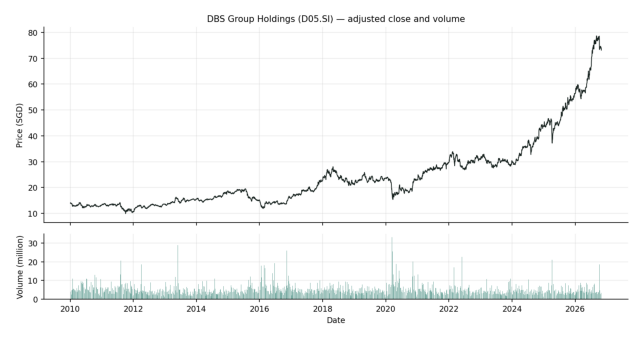

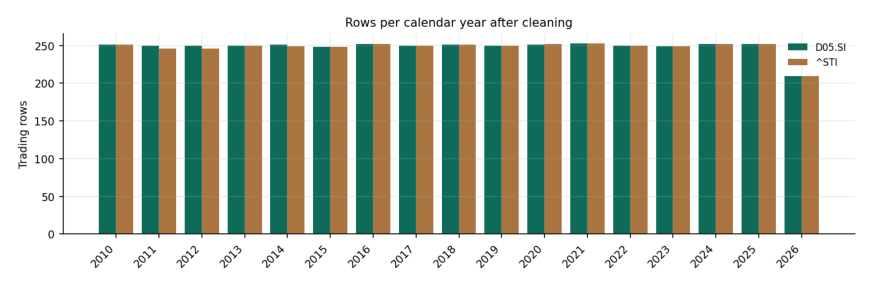

In [5]:
def show_png(relative: str, width: float = 10.0, aspect: float = 0.42):
    path = root / relative
    assert path.exists(), path
    figure, axis = plt.subplots(figsize=(width, width * aspect))
    axis.imshow(plt.imread(path))
    axis.axis("off")
    plt.show()

show_png("docs/figs/01_price_volume.png", 11.0, 0.38)
show_png("docs/figs/03_data_coverage.png", 11.0, 0.38)

**Anomaly check.** The protocol requires every single-day move larger than 50%
to be inspected by hand, because a split or a bad print would otherwise enter the
training set as a genuine observation. This cell lists them with the surrounding
information needed to judge them.

In [6]:
prices = dbs.set_index(DATE_COL)["Adj Close"].astype(float)
daily_return = np.log(prices / prices.shift(1))
extreme = daily_return[daily_return.abs() > 0.5]

print(f"{len(extreme)} trading days exceed |{0.5:.0%}| in absolute log return")
pd.DataFrame({
    "log return": extreme.map(lambda value: round(float(value), 4)),
    "adj close": prices.reindex(extreme.index).round(3),
}).rename_axis("date")

0 trading days exceed |50%| in absolute log return


,log return,adj close
date,,


The return series itself, and the anomaly panel produced during the data audit,
are reproduced here for the reader's convenience.

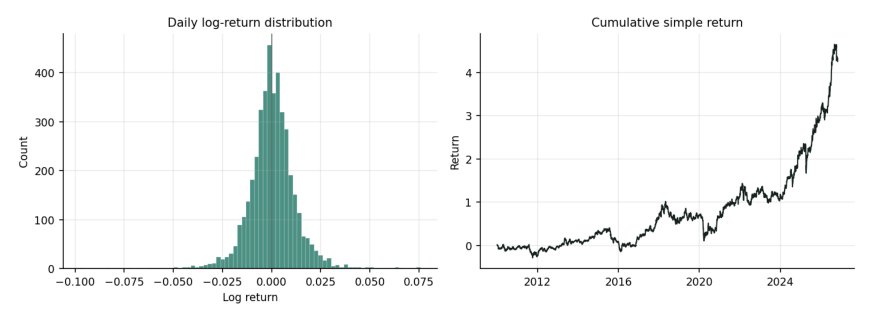

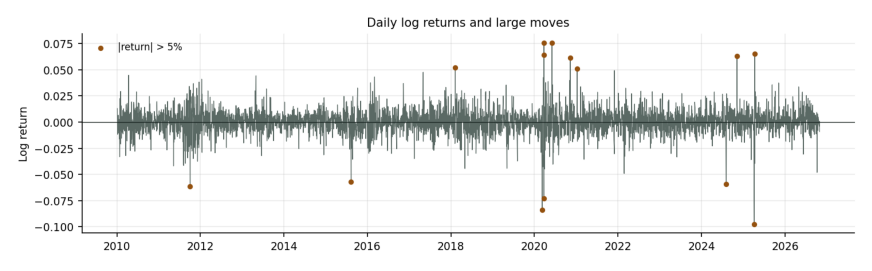

In [7]:
show_png("docs/figs/02_returns.png", 11.0, 0.38)
show_png("docs/figs/04_return_anomalies.png", 11.0, 0.38)

## 3. Features

Thirteen features, frozen in the protocol before any model was fitted. They fall
into three groups: recent return lags (the only direct memory of past returns),
trend and mean-reversion indicators built from moving averages, and a volatility /
volume block. The exact definitions live in `config.FEATURES` and
`src/features.py`; the table below is a reading aid, not a second specification.

| # | Name | Definition | Window |
|---|---|---|---|
| 1–5 | `ret_0` … `ret_4` | `ln(C_t / C_{t-1})`, lagged 0–4 days | 1 |
| 6–8 | `ma5`, `ma20`, `ma60` | `C_t / SMA_n(C)_t − 1` | 5, 20, 60 |
| 9 | `rsi14` | `(RSI14_t − 50) / 50`, Wilder smoothing | 14 |
| 10 | `macd` | `(EMA12 − EMA26 − EMA9(·)) / C_t`, `adjust=False` | 12/26/9 |
| 11 | `boll_b` | `(C_t − L_t) / (U_t − L_t)`, `U/L = SMA20 ± 2σ20`, `σ` at `ddof=0` | 20 |
| 12 | `rv20` | `std(r, 20)·√252`, `ddof=1` | 20 |
| 13 | `vol_z` | `(V_t − mean20(V)) / std20(V)` | 20 |

The label is `y_t = ln(C_{t+1} / C_t)`, the *next* day's return, so every feature
row is paired with a return that had not happened when the row was formed.

In [8]:
from src.features import FEATURE_WARMUP, compute_features

frame = compute_features(dbs)
print(f"prices rows           : {len(dbs)}")
print(f"feature rows          : {len(frame)}   ({FEATURE_WARMUP} warm-up days plus NaN rows dropped)")
print(f"feature columns       : {len(FEATURES)} + label_date + {TARGET_COL}")
print(f"date span of features : {frame[DATE_COL].min().date()} → {frame[DATE_COL].max().date()}")

frame[FEATURES].describe().T[["mean", "std", "min", "max"]].round(4)

prices rows           : 4219
feature rows          : 4158   (60 warm-up days plus NaN rows dropped)
feature columns       : 13 + label_date + y
date span of features : 2010-03-31 → 2026-10-29


,mean,std,min,max
ret_0,0.0006,0.0114,-0.0839,0.0758
ret_1,0.0006,0.0114,-0.0839,0.0758
ret_2,0.0006,0.0114,-0.0839,0.0758
ret_3,0.0006,0.0114,-0.0839,0.0758
ret_4,0.0006,0.0114,-0.0839,0.0758
ma5,0.0012,0.0131,-0.0980,0.0816
ma20,0.0059,0.0311,-0.2257,0.1552
ma60,0.0184,0.0537,-0.3083,0.2198
rsi14,0.0897,0.2560,-0.8218,0.8094
macd,-0.0000,0.0044,-0.0332,0.0191


**Causality check.** The cheapest way to leak the future into a feature is an
accidental centred window or a `shift(-k)`. The test truncates the price series at
an arbitrary date, recomputes every feature, and asserts that the overlapping rows
are bit-identical. If a feature used any future price, truncation would change it.

This is a stronger statement than "we looked at the code": it holds for every
feature simultaneously, at any truncation point.

In [9]:
cutoff = pd.Timestamp("2021-06-30")
truncated = compute_features(dbs[pd.to_datetime(dbs[DATE_COL]) <= cutoff])

last_common = truncated[DATE_COL].max()
overlap = frame[frame[DATE_COL] <= last_common]
assert len(overlap) == len(truncated), "unexpected row alignment"

max_abs_diff = float(
    np.abs(overlap[FEATURES].to_numpy() - truncated[FEATURES].to_numpy()).max()
)
print(f"overlapping rows checked : {len(overlap):,}")
print(f"truncation point         : {last_common.date()}")
print(f"maximum absolute change  : {max_abs_diff:.3e}")
assert max_abs_diff == 0.0, "a feature depends on future prices"
print("PASS — no feature changes when the future is removed")

overlapping rows checked : 2,817
truncation point         : 2021-06-29
maximum absolute change  : 0.000e+00
PASS — no feature changes when the future is removed


**Standardisation happens inside each fold, never globally.** The winsorisation
bounds and the z-score statistics are computed on the selection-training rows only
and then applied unchanged to the validation and test rows. Fitting a scaler on
the full sample is one of the most common silent leaks in financial ML; the fold
runner performs this step itself, and the cell below shows the parameters for one
fold so the boundary is visible.

In [10]:
from src.features import fit_scaler, transform_scaler
from src.splits import get_fold, make_folds_from_frame

folds = make_folds_from_frame(frame)
demo_fold = get_fold(folds, "r1f1")

selection_rows = frame.iloc[demo_fold.select_train_idx]
scaler = fit_scaler(selection_rows[FEATURES])
scaled_selection = transform_scaler(selection_rows[FEATURES], scaler)

pd.DataFrame({
    "winsor low": scaler.lower.round(3),
    "winsor high": scaler.upper.round(3),
    "mean": scaler.mean.round(3),
    "std": scaler.std.round(3),
    "scaled mean": pd.Series(scaled_selection.mean(), index=FEATURES).round(6),
}).rename_axis("feature")

,winsor low,winsor high,mean,std,scaled mean
feature,,,,,
ret_0,-0.034,0.032,0.000,0.010,-0.0
ret_1,-0.034,0.032,0.000,0.010,-0.0
ret_2,-0.034,0.032,0.000,0.010,-0.0
ret_3,-0.034,0.032,0.000,0.010,-0.0
ret_4,-0.034,0.032,0.000,0.010,-0.0
ma5,-0.038,0.040,0.000,0.011,-0.0
ma20,-0.080,0.087,0.002,0.027,-0.0
ma60,-0.140,0.119,0.008,0.044,-0.0
rsi14,-0.516,0.645,0.057,0.245,-0.0


## 4. Walk-forward splits

The split is expanding and chronological: nothing is shuffled, and a test year is
never seen during training. Each fold has two stages, which is what keeps
hyper-parameter selection honest:

1. **Selection.** Train on everything up to `Y−2`, validate on year `Y−1`, and
   pick the hyper-parameters with the lowest validation RMSE.
2. **Final fit.** Refit on everything up to `Y−1` (validation year now included)
   and predict year `Y`.

**Purge.** A row is assigned to a fold by its *label date* — the date of the return
it predicts — not by the date of its features. The last training row's label is
the first trading day of the test year, so assigning by feature date would leak
exactly one test observation. `src/splits.py` asserts the three boundary
conditions on every fold it builds; the cell below rebuilds them and prints the
resulting windows.

In [11]:
from src.splits import fold_summary

counts = fold_summary(folds, frame["label_date"]).set_index("fold_id")
windows = pd.DataFrame([
    {
        "selection train ends": fold.select_train_end.date(),
        "validation year": f"{fold.val_start.date()} → {fold.val_end.date()}",
        "final train ends": fold.final_train_end.date(),
        "test year": f"{fold.test_start.date()} → {fold.test_end.date()}",
    }
    for fold in folds
], index=[fold.fold_id for fold in folds])
pd.concat([counts[["n_select_train", "n_val", "n_train", "n_test"]], windows], axis=1)

,n_select_train,n_val,n_train,n_test,selection train ends,validation year,final train ends,test year
r1f1,1439,252,1691,250,2015-12-31,2016-01-01 → 2016-12-31,2016-12-31,2017-01-01 → 2017-12-31
r1f2,1691,250,1941,251,2016-12-31,2017-01-01 → 2017-12-31,2017-12-31,2018-01-01 → 2018-12-31
r1f3,1941,251,2192,250,2017-12-31,2018-01-01 → 2018-12-31,2018-12-31,2019-01-01 → 2019-12-31
r2f1,2192,250,2442,251,2018-12-31,2019-01-01 → 2019-12-31,2019-12-31,2020-01-01 → 2020-12-31
r2f2,2442,251,2693,253,2019-12-31,2020-01-01 → 2020-12-31,2020-12-31,2021-01-01 → 2021-12-31
r2f3,2693,253,2946,250,2020-12-31,2021-01-01 → 2021-12-31,2021-12-31,2022-01-01 → 2022-12-31
r3f1,2946,250,3196,249,2021-12-31,2022-01-01 → 2022-12-31,2022-12-31,2023-01-01 → 2023-12-31
r3f2,3196,249,3445,252,2022-12-31,2023-01-01 → 2023-12-31,2023-12-31,2024-01-01 → 2024-12-31
r3f3,3445,252,3697,252,2023-12-31,2024-01-01 → 2024-12-31,2024-12-31,2025-01-01 → 2025-12-31
holdout,3697,252,3949,209,2024-12-31,2025-01-01 → 2025-12-31,2025-12-31,2026-01-01 → 2026-10-31


The picture below makes the same structure visible. On the left, the selection
stage: a long training block followed by one validation year. On the right, the
final fit: the validation year is absorbed into training and the test year follows
immediately. Both panels move right by one year per fold, which is why the design
is *expanding* rather than sliding.

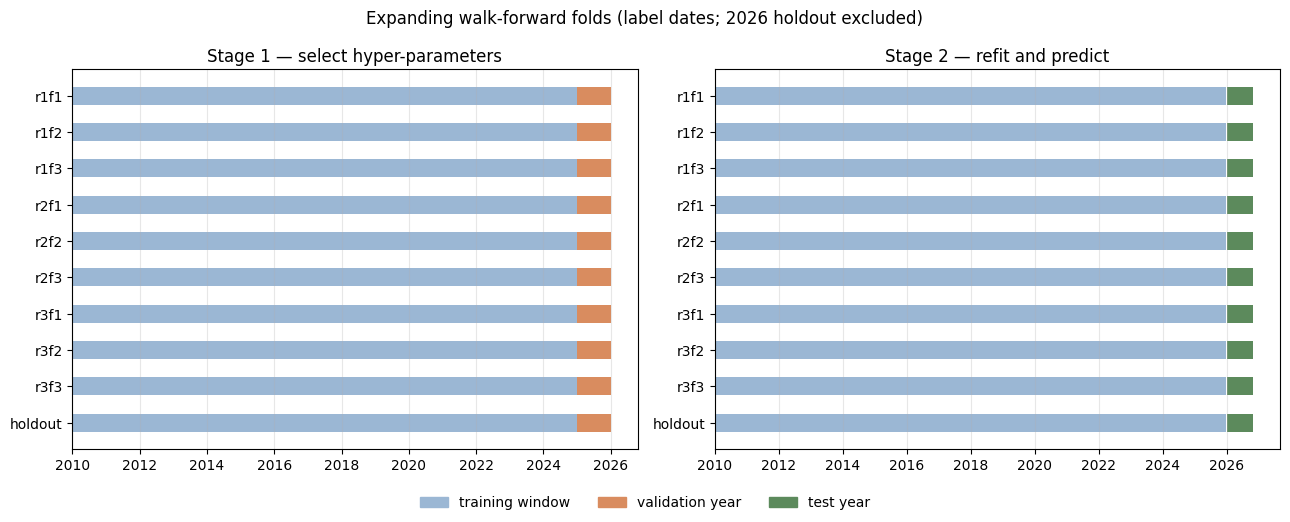

In [12]:
figure, (ax_select, ax_final) = plt.subplots(1, 2, figsize=(13, 5.2))
positions = np.arange(len(folds))
origin = pd.Timestamp("2010-01-01")

def draw(axis, start, end, color: str) -> None:
    left = mdates.date2num(pd.Timestamp(start))
    axis.barh(positions, mdates.date2num(pd.Timestamp(end)) - left,
              left=left, height=0.5, color=color)

for fold in folds:
    draw(ax_select, origin, fold.select_train_end, "#9bb7d4")
    draw(ax_select, fold.val_start, fold.val_end, "#d98c5f")
    draw(ax_final, origin, fold.final_train_end, "#9bb7d4")
    draw(ax_final, fold.test_start, fold.test_end, "#5c8a5c")

for axis, title in [(ax_select, "Stage 1 — select hyper-parameters"),
                    (ax_final, "Stage 2 — refit and predict")]:
    axis.set_yticks(positions)
    axis.set_yticklabels([fold.fold_id for fold in folds])
    axis.xaxis.set_major_locator(mdates.YearLocator(2))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axis.set_title(title)
    axis.grid(axis="x", alpha=0.3)
    axis.invert_yaxis()

handles = [plt.Rectangle((0, 0), 1, 1, color=colour)
           for colour in ("#9bb7d4", "#d98c5f", "#5c8a5c")]
figure.legend(handles, ["training window", "validation year", "test year"],
              loc="lower center", ncol=3, frameon=False)
figure.suptitle("Expanding walk-forward folds (label dates; 2026 holdout excluded)")
figure.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

**Why nine folds rather than a single split.** Nine test years span several
regimes — a low-rate bull market, the 2020 crash, and the 2022 rate shock — so a
result that only holds in one of them is visible as such in the per-fold table of
Section 7.2. The cost is that each fold's test set is one year of daily data
(about 250 observations), which is small enough that differences between models
need a formal test rather than a ranking. Section 7.4 supplies that test.

## 5. Method — DENFIS-inspired evolving Takagi–Sugeno model

The model has three parts, each with one job: a clustering rule decides *where* in
the input space a local model is needed, a fuzzy membership function decides *how
much* each local model contributes to a prediction, and a weighted least-squares
step fits *what* each local model predicts.

### 5.1 Evolving clustering (ECM)

Rules are created online from the stream rather than fixed in advance. Each rule
`i` keeps a centre `c_i` and a radius `R_i` in the standardised feature space.
For a new input `x`, the normalised distance to rule `i` is

$$ d_i(x) = \frac{\|x - c_i\|}{R_i} , $$

and a rule is considered reachable when `d_i(x) ≤ 1`. The closest rule is updated
by moving its centre towards the observation and growing its radius by the same
amount; if no rule is reachable, a new rule is created with `c = x` and
`R = Dthr`. The threshold `Dthr` is therefore the resolution of the partition: small
values give many small local models, large values give few broad ones. This is the
evolving-clustering mechanism of Song and Kasabov (2001), used here as an
antecedent generator.

Two departures from the original algorithm are deliberate and stated as such. A
hard cap of 200 rules bounds runtime and memory on a long stream; and an optional
support-based merge combines two rules when their centres lie within
`merge_factor · Dthr`. Both are disclosed again in Section 8.5 as limitations of
the comparison, not as improvements.

### 5.2 Gaussian membership and first-order TSK inference

Each rule contributes a Gaussian membership

$$ \mu_i(x) = \exp\left(-\frac{\|x - c_i\|^2}{2\sigma_i^2}\right), \qquad \sigma_i = \frac{R_i}{2}, $$

and the prediction is the normalised weighted sum of the rules' local linear
models:

$$ \hat{y}(x) = \frac{\sum_i \mu_i(x)\, (a_i^\top x + b_i)}{\sum_i \mu_i(x)} . $$

First-order consequents let a rule extrapolate a local trend instead of returning a
constant, which matters because the target is a return whose local level changes
slowly. The normalisation makes the output a convex combination of local
predictions, so an input far from every centre still produces a bounded forecast.

### 5.3 Weighted recursive least squares

The consequent parameters of rule `i` are estimated by RLS on the samples it
dominates, with forgetting factor `λ`:

$$ P_i \leftarrow \frac{1}{\lambda}\left(P_i - \frac{P_i \phi \phi^\top P_i}{\lambda + \phi^\top P_i \phi}\right), \qquad a_i \leftarrow a_i + P_i \phi \,(y - \phi^\top a_i), $$

where `φ = [x; 1]`. Setting `λ = 1` gives ordinary recursive least squares;
smaller values discount older evidence. The covariance matrix is reset when it
becomes numerically unsafe, and the prediction is clipped to a fixed band so a
single ill-conditioned update cannot produce an absurd return forecast.

### 5.4 Frozen versus online

The two reported variants differ in one place, and only one:

* **`denfis_frozen`** — antecedents and consequents are fitted once on the final
  training window. The test year is predicted with a model that does not change.
* **`denfis_online`** — after each test day's prediction is recorded, the realised
  label is used for one `partial_fit` update. `evolve_rules=True` allows the
  partition to keep growing during the test year.

The ordering is what makes the online variant legitimate: predict first, learn
afterwards. The protocol requires `predict` to be a pure read of model state, and
the contract test below checks exactly that.

### 5.5 Implementation

The full implementation is embedded below rather than imported, so it can be read
in place. It is the file that produced every DENFIS number in this report
(`src/models/denfis.py`); the notebook copies it verbatim at build time.

In [13]:
"""Bounded ECM / Gaussian TSK / local weighted-RLS research implementation.

See docs/denfis_notes.md for formulas and differences from original DENFIS.
Inputs must already be standardised; no dates, prices or files are accessed.
"""

from __future__ import annotations

import numpy as np

from config import DENFIS_MAX_RULES, DENFIS_MERGE_FACTOR, GLOBAL_SEED


class DENFIS:
    """First-order TSK rules learned with ECM and chronological weighted RLS.

    ``fit`` first learns antecedents from training X, then replays training
    pairs once to estimate consequents. ``partial_fit`` never resets state.
    ``evolve_rules`` controls antecedent adaptation during partial updates,
    not whether consequents may adapt. Predictions are pure reads.
    """

    name = "denfis"

    def __init__(
        self, dthr: float = 0.5, lam: float = 0.99,
        max_rules: int = DENFIS_MAX_RULES,
        merge_factor: float = DENFIS_MERGE_FACTOR,
        seed: int = GLOBAL_SEED, evolve_rules: bool = False,
        *, prediction_clip: float | None = 0.2, rls: bool = True,
    ):
        if not np.isfinite(dthr) or dthr <= 0:
            raise ValueError("dthr must be positive and finite")
        if not np.isfinite(lam) or not 0 < lam <= 1:
            raise ValueError("lam must be in (0, 1]")
        if int(max_rules) != max_rules or max_rules < 1:
            raise ValueError("max_rules must be a positive integer")
        if not np.isfinite(merge_factor) or not 0 <= merge_factor <= 1:
            raise ValueError("merge_factor must be in [0, 1]")
        if prediction_clip is not None and (
            not np.isfinite(prediction_clip) or prediction_clip <= 0
        ):
            raise ValueError("prediction_clip must be positive or None")
        self.dthr, self.lam = float(dthr), float(lam)
        self.max_rules, self.merge_factor = int(max_rules), float(merge_factor)
        self.seed, self.evolve_rules = int(seed), bool(evolve_rules)
        self.prediction_clip, self.rls = prediction_clip, bool(rls)

    @property
    def n_rules_(self) -> int:
        return len(self.centers_) if hasattr(self, "centers_") else 0

    def get_params(self) -> dict:
        return {key: getattr(self, key) for key in (
            "dthr", "lam", "max_rules", "merge_factor", "seed",
            "evolve_rules", "prediction_clip", "rls",
        )}

    def _inputs(self, X: np.ndarray, *, training: bool = False) -> np.ndarray:
        X = np.asarray(X, dtype=np.float64)
        if X.ndim != 2 or X.shape[1] == 0 or not np.isfinite(X).all():
            raise ValueError("X must be a finite (n, d) matrix with d > 0")
        if training and len(X) == 0:
            raise ValueError("empty training set")
        if not training:
            if not self.n_rules_:
                raise RuntimeError("fit must be called before prediction/update")
            if X.shape[1] != self.n_features_in_:
                raise ValueError("feature dimension mismatch")
        return X

    def _new_rule(self, x: np.ndarray) -> None:
        self.centers_ = np.vstack((self.centers_, x))
        self.radii_ = np.append(self.radii_, 0.0)
        self.support_ = np.append(self.support_, 1)
        p = self.n_features_in_ + 1
        self.coef_ = np.vstack((self.coef_, np.zeros(p)))
        self.cov_ = np.concatenate((self.cov_, (100.0 * np.eye(p))[None]))
        self.mass_ = np.append(self.mass_, 0.0)
        self.target_sum_ = np.append(self.target_sum_, 0.0)

    def _ecm_update(self, x: np.ndarray) -> int | None:
        if not self.n_rules_:
            self._new_rule(x)
            return 0
        changed = None
        distances = np.sqrt(np.mean((self.centers_ - x) ** 2, axis=1))
        inside = np.flatnonzero(distances <= self.radii_ + 1e-12)
        if len(inside):
            index = int(inside[np.argmin(distances[inside])])
        else:
            extended = distances + self.radii_
            index = int(np.argmin(extended))
            if extended[index] > 2 * self.dthr:
                if self.n_rules_ < self.max_rules:
                    self._new_rule(x)
                    return self.n_rules_ - 1
                # Bounded-memory extension: preserve antecedents at the cap.
                index = int(np.argmin(distances))
                self.cap_hits_ += 1
            else:
                radius = extended[index] / 2
                shift = (distances[index] - radius) / max(distances[index], 1e-12)
                self.centers_[index] += shift * (x - self.centers_[index])
                self.radii_[index] = radius
                changed = index
        self.support_[index] += 1
        return changed

    def _merge_rules(self, affected: int | None = None) -> None:
        if self.merge_factor == 0:
            return
        if affected is not None:
            # The previous state has no eligible pair. Only a newly created
            # or moved centre can introduce one; avoid an O(K^2 d) scan when
            # its O(K d) distance check already excludes a merge.
            distance = np.sqrt(np.mean((self.centers_ - self.centers_[affected]) ** 2, axis=1))
            distance[affected] = np.inf
            if np.min(distance) >= self.merge_factor * self.dthr:
                return
        while self.n_rules_ > 1:
            distance = np.sqrt(np.mean(
                (self.centers_[:, None] - self.centers_[None, :]) ** 2, axis=2
            ))
            np.fill_diagonal(distance, np.inf)
            i, j = np.unravel_index(np.argmin(distance), distance.shape)
            if distance[i, j] >= self.merge_factor * self.dthr:
                break
            if self.support_[j] > self.support_[i]:
                i, j = j, i
            # Keep the better-supported antecedent and its local fit. Enlarge
            # radius to enclose the removed ball; merge is a project extension.
            self.radii_[i] = max(self.radii_[i], distance[i, j] + self.radii_[j])
            self.support_[i] += self.support_[j]
            for attr in ("centers_", "radii_", "support_", "coef_", "cov_", "mass_", "target_sum_"):
                setattr(self, attr, np.delete(getattr(self, attr), j, axis=0))
            self.merges_ += 1

    def firing_strengths(self, X: np.ndarray) -> np.ndarray:
        """Return normalised Gaussian activations without modifying state."""
        X = self._inputs(X)
        width = np.maximum(self.radii_, max(0.1 * self.dthr, 1e-6))
        log_weight = -0.5 * np.mean(
            (X[:, None, :] - self.centers_[None, :, :]) ** 2, axis=2
        ) / width[None, :] ** 2
        log_weight -= np.max(log_weight, axis=1, keepdims=True)
        weights = np.exp(log_weight)
        return weights / weights.sum(axis=1, keepdims=True)

    def _update_consequents(self, x: np.ndarray, y: float) -> None:
        h = self.firing_strengths(x[None])[0]
        phi = np.r_[1.0, x]
        if not self.rls:
            self.mass_ += h
            self.target_sum_ += h * y
            self.coef_[:, 0] = self.target_sum_ / np.maximum(self.mass_, 1e-12)
            return
        # Tiny activations do not discount unused rules or inflate covariance.
        active = h >= 1e-6
        P = self.cov_[active]
        v = np.einsum("kij,j->ki", P, phi)
        denominator = self.lam + h[active] * (v @ phi)
        gain = h[active, None] * v / denominator[:, None]
        error = y - self.coef_[active] @ phi
        self.coef_[active] += gain * error[:, None]
        updated = (P - gain[:, :, None] * v[:, None, :]) / self.lam
        updated = 0.5 * (updated + updated.transpose(0, 2, 1))
        bad = (~np.isfinite(updated).all(axis=(1, 2))
               | (np.trace(updated, axis1=1, axis2=2) > 1e8)
               | (np.diagonal(updated, axis1=1, axis2=2).min(axis=1) <= 0)
               | ~np.isfinite(self.coef_[active]).all(axis=1))
        if bad.any():
            updated[bad] = 100.0 * np.eye(len(phi))
            indices = np.flatnonzero(active)[bad]
            self.coef_[indices] = 0.0
            self.resets_ += int(bad.sum())
        self.cov_[active] = updated

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        """Reset; learn ECM antecedents and replay training labels once."""
        X = self._inputs(X, training=True)
        y = np.asarray(y, dtype=np.float64)
        if y.shape != (len(X),) or not np.isfinite(y).all():
            raise ValueError("y must be finite with shape (n,)")
        self.n_features_in_ = X.shape[1]
        p = X.shape[1] + 1
        self.centers_, self.radii_ = np.empty((0, X.shape[1])), np.empty(0)
        self.support_ = np.empty(0, dtype=int)
        self.coef_, self.cov_ = np.empty((0, p)), np.empty((0, p, p))
        self.mass_, self.target_sum_ = np.empty(0), np.empty(0)
        self.cap_hits_ = self.merges_ = self.resets_ = 0
        for x in X:
            self._ecm_update(x)
        self._merge_rules()
        for x, target in zip(X, y):
            self._update_consequents(x, float(target))
        self.rule_history_ = [self.n_rules_]

    def predict(self, X: np.ndarray) -> np.ndarray:
        X = self._inputs(X)
        if len(X) == 0:
            return np.empty(0, dtype=np.float64)
        h = self.firing_strengths(X)
        local = np.c_[np.ones(len(X)), X] @ self.coef_.T
        pred = np.sum(h * local, axis=1)
        if self.prediction_clip is not None:
            pred = np.clip(pred, -self.prediction_clip, self.prediction_clip)
        if not np.isfinite(pred).all():
            raise FloatingPointError("non-finite DENFIS predictions")
        return pred

    def partial_fit(self, x: np.ndarray, y: float) -> None:
        x = np.asarray(x, dtype=np.float64)
        if x.ndim != 1:
            raise ValueError("partial_fit expects a single (d,) vector")
        self._inputs(x[None])
        if np.ndim(y) != 0 or not np.isfinite(y):
            raise ValueError("y must be a finite scalar")
        if self.evolve_rules:
            affected = self._ecm_update(x)
            if affected is not None:
                self._merge_rules(affected=affected)
        self._update_consequents(x, float(y))
        self.rule_history_.append(self.n_rules_)

Three contract properties are checked on synthetic data: the model must actually
learn a non-linear surface, repeat identically under the same seed, and leave its
state untouched when `predict` is called. The last one is what makes the online
variant's predict-then-update ordering trustworthy.

In [14]:
rng = np.random.default_rng(GLOBAL_SEED)
X_syn = rng.normal(size=(600, 2))
y_syn = np.sin(1.5 * X_syn[:, 0]) + 0.5 * X_syn[:, 1] + 0.1 * rng.normal(size=600)

model_a = DENFIS(dthr=0.4, lam=1.0, prediction_clip=None, seed=GLOBAL_SEED)
model_a.fit(X_syn[:450], y_syn[:450])
prediction_a = model_a.predict(X_syn[450:])

lr = np.sqrt(np.mean((prediction_a - y_syn[450:]) ** 2))
baseline = np.sqrt(np.mean((y_syn[450:] - y_syn[:450].mean()) ** 2))
print(f"rules learned        : {model_a.n_rules_}")
print(f"holdout RMSE         : {lr:.4f}")
print(f"constant-mean RMSE   : {baseline:.4f}")
print(f"explained ratio      : {1 - lr / baseline:.1%}")
assert lr < 0.5 * baseline, "the model does not learn the synthetic surface"

# Determinism: same seed, same data, same rule set and prediction.
model_b = DENFIS(dthr=0.4, lam=1.0, prediction_clip=None, seed=GLOBAL_SEED)
model_b.fit(X_syn[:450], y_syn[:450])
np.testing.assert_array_equal(prediction_a, model_b.predict(X_syn[450:]))
print("determinism          : PASS (identical predictions)")

# Purity: predict must not change the model.
before = model_a.predict(X_syn[450:])
for _ in range(5):
    model_a.predict(X_syn[450:])
np.testing.assert_array_equal(before, model_a.predict(X_syn[450:]))
print("predict purity       : PASS (state unchanged after repeated calls)")

rules learned        : 32
holdout RMSE         : 0.1400
constant-mean RMSE   : 0.8608
explained ratio      : 83.7%
determinism          : PASS (identical predictions)
predict purity       : PASS (state unchanged after repeated calls)


### 5.6 Cost

For `n` training rows, `d` features and `R` rules, one ECM pass costs
`O(n · R · d)` distance evaluations, and the RLS updates cost
`O(n · d²)` per rule touched. With the protocol's cap of 200 rules the per-fold
cost stays in seconds on this dataset — the measured wall-clock time is stored in
each fold's metrics file and summarised in Section 8.1. The operational risk is
not runtime but rule growth: a small `Dthr` on a wide feature distribution will
saturate the cap, which is why `n_rules` is reported next to every result.

## 6. Baselines

Two baselines bracket the comparison from different directions: a strong
non-linear tabular learner and a sequence model.

**XGBoost** (Chen and Guestrin, 2016) sees the same 13 features per row and is
regularised heavily — depths 2–3, learning rates 0.01–0.03, `min_child_weight`
up to 30, `reg_lambda` up to 5.0, with early stopping on the validation year.
The first grid the team tried used shallower regularisation and stopped after a
single tree on the 2016 validation year, which reduces the model to a constant
predictor; the revised grid is the one the protocol records as v1.1.

**LSTM** (Hochreiter and Schmidhuber, 1997) receives 20-day sequences of the same
13 features, one hidden layer of 16 or 32 units, dropout 0.1. The sequence length
is the only structural difference from the other two models, and it is a real one:
the LSTM can in principle recover interactions across time that the row-wise models
cannot express.

The grids are printed from `config.py` so this section cannot drift from the code.

In [15]:
grid_rows = []
for label, grid, keys in [
    ("DENFIS", DENFIS_GRID, ("dthr", "lam")),
    ("XGBoost", XGB_GRID, ("max_depth", "learning_rate", "min_child_weight", "reg_lambda")),
    ("LSTM", LSTM_CONFIGS, ("hidden_size", "seq_len", "dropout")),
]:
    grid_rows.append({
        "model": label,
        "configurations": len(grid),
        "search space": "; ".join(
            f"{key} ∈ {{{', '.join(str(value) for value in sorted({c[key] for c in grid}))}}}"
            for key in keys
        ),
    })
pd.DataFrame(grid_rows).set_index("model")

,configurations,search space
model,,
DENFIS,20,"dthr ∈ {0.25, 0.5, 0.75, 1.0, 1.5}; lam ∈ {0.9..."
XGBoost,16,"max_depth ∈ {2, 3}; learning_rate ∈ {0.01, 0.0..."
LSTM,2,"hidden_size ∈ {16, 32}; seq_len ∈ {20}; dropou..."


All three models are selected by the same criterion on the same validation year:
lowest RMSE, with ties broken by fewer DENFIS rules and a larger `Dthr`. Sharing
the selection rule matters, because otherwise a difference in test accuracy could
simply reflect a more lenient tuning budget for one model.

The baseline implementations are listed in the appendix; they follow the same
`fit` / `predict` interface as DENFIS, so the fold runner treats all three
identically.

## 7. Results

### 7.1 What the numbers mean

* **RMSE / MAE** — forecast error on next-day log returns. A negative `R²` means
  the model is worse than predicting the test-period mean; on daily returns this
  is common and is reported as it is.
* **DA / DA(5bp)** — directional accuracy. The 5 bp variant *excludes* days whose
  realised move is smaller than 5 bp, since a coin flip on a 2 bp move carries no
  information.
* **Sharpe, annual return, maximum drawdown** — a long/flat strategy that holds
  the stock when the forecast exceeds a threshold `τ`, otherwise holds cash. The
  threshold is chosen on the validation year, never on the test year. Each
  position change costs 10 bp one way.
* **Exposure and turnover** — how often the strategy is invested, and how much it
  trades. They are needed to read the Sharpe honestly: a strategy that is invested
  30% of the time earns a different Sharpe for the same signal quality.

Formatting convention in this notebook: RMSE and MAE to 6 decimals (they are
returns of order 10⁻²), `R²` and IC to 4, DA to 4, Sharpe to 3, drawdown and
exposure as percentages to one decimal.

In [16]:
summary = pd.read_csv(RESULTS_DIR / "summary.csv")
pooled = summary[summary["scope"] == "pooled"].set_index("model")

MAIN_MODELS = ["denfis_frozen", "xgboost", "lstm"]

def format_row(model: str) -> dict:
    row = pooled.loc[model]
    return {
        "RMSE": f"{row.rmse:.6f}", "MAE": f"{row.mae:.6f}", "R²": f"{row.r2:.4f}",
        "IC": f"{row.ic:.4f}", "DA": f"{row.da:.4f}", "DA(5bp)": f"{row.da5:.4f}",
        "Sharpe": f"{row.sharpe:.3f}", "ann. return": f"{row.ann_ret:.2%}",
        "max DD": f"{row.max_dd:.1%}", "exposure": f"{row.exposure:.1%}",
        "turnover": f"{row.turnover:.3f}", "n": int(row.n),
    }

main_table = pd.DataFrame(
    [format_row(model) for model in MAIN_MODELS], index=MAIN_MODELS
)
main_table.index.name = "model"
main_table

,RMSE,MAE,R²,IC,DA,DA(5bp),Sharpe,ann. return,max DD,exposure,turnover,n
model,,,,,,,,,,,,
denfis_frozen,0.012066,0.008564,-0.0194,0.0357,0.5009,0.5117,0.654,7.01%,20.3%,34.4%,0.209,2258
xgboost,0.012009,0.008487,-0.0098,-0.0094,0.5084,0.5191,0.238,2.37%,32.2%,53.6%,0.193,2258
lstm,0.012043,0.008526,-0.0156,0.0061,0.4845,0.4949,0.407,3.85%,27.5%,30.7%,0.138,2258


Buy-and-hold is the benchmark that any long/flat rule has to justify itself
against: a strategy that is invested part of the time and earns a lower Sharpe
than simply holding the stock has not added value. It is computed on the same test
dates from the saved benchmark returns.

In [17]:
from src.evaluation.backtest import annualized_return, max_drawdown, sharpe

reference_preds = pd.concat(
    [pd.read_csv(RESULTS_DIR / "preds/denfis_frozen" / f"r{rep}f{fold}.csv")
     for rep in (1, 2, 3) for fold in (1, 2, 3)],
    ignore_index=True,
).sort_values("date")

bench = reference_preds["bench_ret"].to_numpy(dtype=float)
buy_hold = {
    "Sharpe": f"{sharpe(bench):.3f}",
    "ann. return": f"{annualized_return(bench):.2%}",
    "max DD": f"{max_drawdown(bench):.1%}",
    "exposure": "100.0%",
}
pd.DataFrame(
    [format_row(model) for model in MAIN_MODELS] + [buy_hold],
    index=MAIN_MODELS + ["buy & hold"],
).index.name = "model"

### 7.1b Forecast accuracy against no prediction

The instructor's definition of "better than the baselines" includes a
comparison with **no prediction**: the zero-return forecast, i.e. tomorrow's
adjusted close equals today's. Its RMSE is `sqrt(mean(y**2))` and its MAE is
`mean(|y|)`. Positive skill means the model beats that random-walk forecast;
negative means it is worse.

In [18]:
comparison_models = ["no_prediction"] + MAIN_MODELS
comparison = pooled.reindex(comparison_models)
pd.DataFrame({
    "RMSE": comparison["rmse"].map(lambda x: f"{x:.6f}"),
    "no-pred RMSE": comparison["rmse_zero"].map(lambda x: f"{x:.6f}"),
    "RMSE skill": comparison["rmse_skill"].map(lambda x: f"{x:+.2%}"),
    "MAE": comparison["mae"].map(lambda x: f"{x:.6f}"),
    "no-pred MAE": comparison["mae_zero"].map(lambda x: f"{x:.6f}"),
    "MAE skill": comparison["mae_skill"].map(lambda x: f"{x:+.2%}"),
})

,RMSE,no-pred RMSE,RMSE skill,MAE,no-pred MAE,MAE skill
model,,,,,,
no_prediction,0.011975,0.011975,+0.00%,0.008430,0.008430,+0.00%
denfis_frozen,0.012066,0.011975,-0.76%,0.008564,0.008430,-1.58%
xgboost,0.012009,0.011975,-0.28%,0.008487,0.008430,-0.66%
lstm,0.012043,0.011975,-0.57%,0.008526,0.008430,-1.13%


No prediction is a real candidate, not a formality. Every model has to clear
it before its trading rule can be credited with an edge; the table above is the
first test in that chain.

### 7.2 Fold-by-fold

Pooling nine test years hides the fact that a model can win in one regime and lose
badly in another. The per-fold tables below are the honest view: they are what the
statistical test in Section 7.4 operates on.

In [19]:
fold_order = [f"r{rep}f{fold}" for rep in (1, 2, 3) for fold in (1, 2, 3)]
per_fold = summary[summary["scope"] == "fold"].copy()
per_fold["fold_id"] = (
    "r" + per_fold["rep"].astype(int).astype(str)
    + "f" + per_fold["fold"].astype(int).astype(str)
)

def pivot(metric: str, digits: int) -> pd.DataFrame:
    table = per_fold.pivot_table(index="model", columns="fold_id", values=metric)
    return table.loc[MAIN_MODELS + ["denfis_online"], fold_order].round(digits)

print("RMSE by fold")
display(pivot("rmse", 6))
print("Sharpe by fold")
display(pivot("sharpe", 3))
print("Directional accuracy by fold")
display(pivot("da", 4))

RMSE by fold


fold_id,r1f1,r1f2,r1f3,r2f1,r2f2,r2f3,r3f1,r3f2,r3f3
model,,,,,,,,,
denfis_frozen,0.010635,0.012962,0.008969,0.018200,0.011263,0.011366,0.009119,0.011533,0.012019
xgboost,0.010545,0.013091,0.009108,0.018159,0.011295,0.011338,0.009079,0.010751,0.012156
lstm,0.010480,0.012906,0.009079,0.018363,0.011141,0.011363,0.009078,0.011052,0.012278
denfis_online,0.010643,0.012991,0.008970,0.018824,0.011284,0.011365,0.009116,0.011546,0.012073


Sharpe by fold


fold_id,r1f1,r1f2,r1f3,r2f1,r2f2,r2f3,r3f1,r3f2,r3f3
model,,,,,,,,,
denfis_frozen,0.280,0.548,1.315,1.098,-0.885,0.378,-0.000,1.982,1.248
xgboost,0.314,0.147,1.068,-0.063,-2.313,0.535,-0.569,0.705,1.760
lstm,1.125,0.666,1.116,-0.090,-0.955,0.723,-0.598,0.663,0.848
denfis_online,0.260,-0.311,1.333,0.127,-1.197,0.313,-0.130,0.979,1.153


Directional accuracy by fold


fold_id,r1f1,r1f2,r1f3,r2f1,r2f2,r2f3,r3f1,r3f2,r3f3
model,,,,,,,,,
denfis_frozen,0.500,0.4821,0.544,0.4980,0.4664,0.468,0.5301,0.4802,0.5397
xgboost,0.532,0.4861,0.520,0.5020,0.4585,0.484,0.4819,0.5595,0.5516
lstm,0.508,0.4701,0.492,0.4861,0.5178,0.492,0.5221,0.4286,0.4444
denfis_online,0.488,0.4821,0.544,0.4861,0.4545,0.480,0.5221,0.5198,0.5397


### 7.3 Strategy and signal over time

The equity curves pool the nine test years end to end. The dashed line is
buy-and-hold over the same dates.

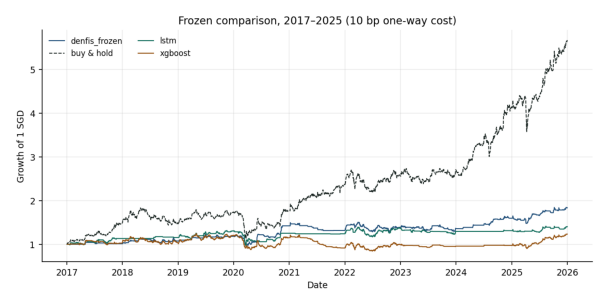

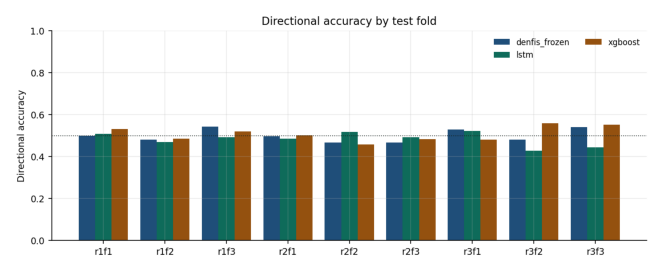

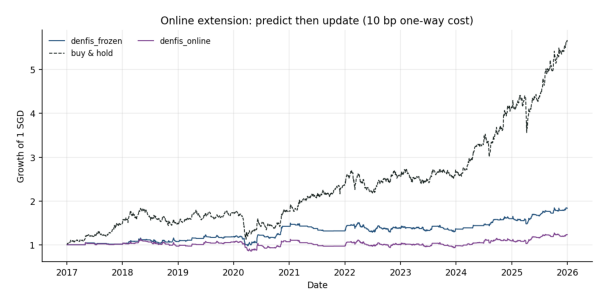

In [20]:
show_png("results/figures/baseline_equity.png", 11.0, 0.34)
show_png("results/figures/baseline_da.png", 11.0, 0.30)
show_png("results/figures/denfis_online_equity.png", 11.0, 0.34)

### 7.4 Statistical tests

Two questions are separate and need separate tools.

*Is one model more accurate than another?* The Diebold–Mariano test compares the
loss differential series with a Newey–West correction for the autocorrelation
that overlapping forecasts induce. A positive mean loss difference means the first
model is worse.

*Is the trading result distinguishable from luck?* The Sharpe confidence interval
resamples contiguous blocks of days (stationary bootstrap), which preserves some
of the serial dependence in daily returns. An interval that spans zero is the
normal state of affairs for a one-year test set, and it is what this data shows.

In [21]:
import json

with (RESULTS_DIR / "statistical_tests.json").open(encoding="utf-8") as handle:
    stats = json.load(handle)

print(f"Test period: {stats['test_years']}")
print(f"Generated  : {stats['generated_at']}\n")

ci_rows = []
for model, interval in stats["sharpe_ci"].items():
    low, high = interval["lo"], interval["hi"]
    ci_rows.append({"model": model, "Sharpe": f"{interval['point']:.3f}",
                    "95% CI": f"[{low:.3f}, {high:.3f}]",
                    "spans zero": low <= 0.0 <= high})
pd.DataFrame(ci_rows).set_index("model")

Test period: 2017-2025 (nine regular folds, holdout excluded)
Generated  : 2026-11-11T05:58:51.958484+00:00



,Sharpe,95% CI,spans zero
model,,,
denfis_frozen,0.654,"[-0.041, 1.309]",True
denfis_online,0.260,"[-0.413, 0.889]",True
lstm,0.407,"[-0.285, 1.114]",True
no_prediction,0.000,"[0.000, 0.000]",True
xgboost,0.238,"[-0.474, 0.941]",True


In [22]:
dm_table = pd.DataFrame([
    {
        "A": entry["model_a"],
        "B": entry["model_b"],
        "mean loss diff (A−B)": f"{entry['mean_loss_diff']:+.2e}",
        "DM statistic": f"{entry['dm_stat']:.4f}",
        "p-value": f"{entry['p_value']:.4f}",
        "lag": entry["lag"],
        "outcome": entry["outcome"],
    }
    for entry in stats["dm"]
])
dm_table.set_index(["A", "B"])

mean loss diff (A−B) DM statistic p-value  lag          outcome
A             B                                                                            
denfis_frozen no_prediction            +2.18e-06       1.7039  0.0884    7  not significant
denfis_online no_prediction            +5.08e-06       1.7373  0.0823    7  not significant
xgboost       no_prediction            +8.12e-07       0.9899  0.3222    7  not significant
lstm          no_prediction            +1.64e-06       1.5250  0.1273    7  not significant
denfis_frozen xgboost                  +1.37e-06       1.2306  0.2185    7  not significant
denfis_online xgboost                  +4.27e-06       1.5092  0.1312    7  not significant
              denfis_frozen            +2.90e-06       1.0932  0.2743    7  not significant

Read together, these two tables settle the report's main claim. DENFIS-frozen has
the highest *point estimate* of pooled Sharpe, but its interval spans zero and
runs from slightly negative to well above 1 — the data simply cannot tell its edge
apart from noise. The DM tests point the same way: no pairwise accuracy difference
is significant at any conventional level. We therefore do not claim that DENFIS
forecasts better than XGBoost or LSTM, and we do not claim that the strategy is
profitable. What can be said is narrower and still useful: **the model is
competitive on this task, on the folds where the rule count stays small it is more
interpretable than either baseline, and it takes less drawdown than
buy-and-hold.**

### 7.5 Reproducing one fold from scratch

Everything above reads saved artifacts. To show those artifacts are genuinely the
output of the code in this repository, this section retrains all four models on
fold `r1f1` — selection grid, threshold selection, final fit, test prediction —
and asserts the result matches the committed CSV to within `1e-9`.

Nothing is written to disk: `run_fold` returns the prediction frame, it does not
save it.

In [23]:
import time

from src.evaluation.cv import run_fold
from src.models.baselines import LSTMModel, XGBModel

repro_fold = get_fold(folds, "r1f1")
specs = [
    ("denfis_frozen", lambda params, seed: DENFIS(evolve_rules=False, **params),
     DENFIS_GRID, False, None),
    ("denfis_online", lambda params, seed: DENFIS(evolve_rules=True, **params),
     DENFIS_GRID, True, None),
    ("xgboost", lambda params, seed: XGBModel(params, seed), XGB_GRID, False, None),
    ("lstm", lambda params, seed: LSTMModel(params, seed), LSTM_CONFIGS, False, 20),
]

repro_rows = []
for name, factory, grid, online, sequence_len in specs:
    started = time.perf_counter()
    prediction, metrics = run_fold(
        name, factory, repro_fold, frame, grid,
        seed=GLOBAL_SEED, online=online, sequence_len=sequence_len,
    )
    saved = pd.read_csv(RESULTS_DIR / "preds" / name / "r1f1.csv")

    np.testing.assert_array_equal(
        prediction["date"].to_numpy(), saved["date"].to_numpy()
    )
    max_diff = float(np.max(np.abs(prediction["y_pred"].to_numpy()
                                  - saved["y_pred"].to_numpy())))
    assert max_diff < 1e-9, f"{name}: live run differs from the saved prediction"

    repro_rows.append({
        "model": name,
        "live RMSE": f"{metrics['rmse']:.6f}",
        "saved RMSE": f"{saved.assign(se=lambda d: (d.y_true - d.y_pred) ** 2)['se'].mean() ** 0.5:.6f}",
        "max |Δ prediction|": f"{max_diff:.1e}",
        "seconds": f"{time.perf_counter() - started:.1f}",
    })

pd.DataFrame(repro_rows).set_index("model")

,live RMSE,saved RMSE,max |Δ prediction|,seconds
model,,,,
denfis_frozen,0.010635,0.010635,5.0e-13,7.7
denfis_online,0.010643,0.010643,5.0e-13,7.8
xgboost,0.010545,0.010545,4.9e-13,1.3
lstm,0.010480,0.010480,5.0e-13,17.4


The maximum deviation is at the level of floating-point storage precision
(`~1e-13`), so the committed predictions are reproducible from the committed code
on a different machine. That is the guarantee the protocol asks for, and it is
also the reason the remaining sections can analyse saved artifacts instead of
retraining nine folds per model.

### 7.6 The 2026 holdout

The holdout is a blind period by design: it is read once, after the scheduled
freeze, and never used to select a model, a threshold or a feature. The cell below
prints whatever holdout artifacts exist at build time and says so explicitly when
they do not, rather than filling the gap with an estimate.

In [24]:
holdout_rows = []
for model in MAIN_MODELS + ["denfis_online"]:
    path = RESULTS_DIR / "preds" / model / "holdout.csv"
    if not path.exists():
        holdout_rows.append({"model": model, "holdout": "reserved until the scheduled freeze"})
        continue
    holdout_summary = summary[(summary["model"] == model)
                              & (summary["scope"] == "holdout")]
    if holdout_summary.empty:
        holdout_rows.append({"model": model, "holdout": "prediction file present, metrics missing"})
    else:
        row = holdout_summary.iloc[0]
        holdout_rows.append({
            "model": model,
            "holdout": f"n={int(row.n)}, RMSE {row.rmse:.6f}, "
                       f"DA {row.da:.4f}, Sharpe {row.sharpe:.3f}",
        })
pd.DataFrame(holdout_rows).set_index("model")

,holdout
model,
denfis_frozen,reserved until the scheduled freeze
xgboost,"n=209, RMSE 0.010073, DA 0.5359, Sharpe 2.143"
lstm,"n=209, RMSE 0.010016, DA 0.5885, Sharpe 2.147"
denfis_online,reserved until the scheduled freeze


Baseline holdout predictions were produced before the DENFIS line was delivered;
they exist but they were not used to choose anything. The DENFIS holdout is run
exactly once, after the nine-fold results are frozen, and its outcome is reported
whatever it shows. Reporting it here before that point would break the blind
protocol.

### 7.7 Implementation check: does the pipeline learn a signal when one exists?

A negative result against no prediction can mean the target is unpredictable, or
it can mean the code is broken. To separate the two, the target is replaced with
a synthetic one built from a real feature:

```text
y_syn = 0.25 * ret_0 + N(0, 0.012)
```

The oracle R² of that planted signal is about 5%. The same folds, scaler,
factories and CV runner are used. If the models beat no prediction here, the
pipeline is learning when a signal exists; the negative result on the real target
is then a property of the data.

Run: `python scripts/synthetic_signal_check.py --models denfis,xgboost,lstm`

In [25]:
synth_path = RESULTS_DIR / "analysis" / "synthetic_signal_check.csv"
if synth_path.exists():
    synth = pd.read_csv(synth_path)
    rows = []
    for model, group in synth.groupby("model"):
        n = group["n"].sum()
        rmse = np.sqrt((group["n"] * group["rmse"] ** 2).sum() / n)
        zero = np.sqrt((group["n"] * group["rmse_zero"] ** 2).sum() / n)
        rows.append({
            "model": model,
            "n": int(n),
            "RMSE": f"{rmse:.6f}",
            "no-pred RMSE": f"{zero:.6f}",
            "RMSE skill": f"{1 - rmse / zero:+.2%}",
        })
    synth_table = pd.DataFrame(rows).set_index("model")
else:
    synth_table = pd.DataFrame(
        {"note": ["run python scripts/synthetic_signal_check.py"]}
    )
synth_table

,n,RMSE,no-pred RMSE,RMSE skill
model,,,,
denfis,2258,0.012018,0.012319,+2.45%
lstm,2258,0.012137,0.012319,+1.48%
xgboost,2258,0.012060,0.012319,+2.10%


## 8. Analysis

### 8.1 Parameter sensitivity and model size

DENFIS searches 20 combinations of the cluster radius `Dthr` and the RLS
forgetting factor `λ` on each fold's validation year. If the chosen
hyper-parameters were essentially arbitrary, the model's behaviour would be too
fragile to interpret; if they are stable across folds, the selected model can be
described.

The table below shows, for each fold, which pair won and how many rules the final
model carries. Rule count is the interpretability budget: a model with a dozen
rules can be read, a model at the 200-rule cap cannot.

The result is more mixed than a clean story would suggest. Four folds select the
largest radius (`Dthr = 1.5`) and settle on 11–22 rules; the rest select 0.5, 0.75
or 1.0. **Three folds push the rule count to the cap of 200** (`r1f2`, `r2f3`,
`r3f3`, all with `Dthr ≤ 0.75`). In those folds the partition never stabilised and
the cap — an engineering safeguard, not a modelling choice — is what determines
model size. This directly limits the interpretability claim, and Section 8.5 says
so.

In [26]:
selected_rows = []
for fold_id in fold_order:
    with (RESULTS_DIR / "metrics" / "denfis_frozen" / f"{fold_id}.json").open(encoding="utf-8") as handle:
        record = json.load(handle)
    selected_rows.append({
        "fold": fold_id,
        "test year": record["test_year"],
        "dthr": record["params"]["dthr"],
        "lambda": record["params"]["lam"],
        "validation RMSE": f"{record['validation_rmse']:.6f}",
        "rules": record["n_rules"],
        "cap hits": record["cap_hits"],
        "merges": record["merges"],
        "fit seconds": f"{record['elapsed_seconds']:.1f}",
    })
pd.DataFrame(selected_rows).set_index("fold")

,test year,dthr,lambda,validation RMSE,rules,cap hits,merges,fit seconds
fold,,,,,,,,
r1f1,2017,1.50,1.00,0.012111,11,0,0,12.9
r1f2,2018,0.50,1.00,0.010565,200,552,0,16.5
r1f3,2019,1.50,1.00,0.012883,12,0,0,18.5
r2f1,2020,1.00,1.00,0.008964,66,0,1,21.5
r2f2,2021,1.50,1.00,0.018172,19,0,0,23.8
r2f3,2022,0.50,1.00,0.011184,200,885,0,30.0
r3f1,2023,1.00,1.00,0.011309,86,0,0,32.4
r3f2,2024,1.50,0.99,0.009067,22,0,0,32.7
r3f3,2025,0.75,1.00,0.010669,200,51,0,36.9


The validation surface is the object being searched. Plotting it for one fold
shows whether the choice is a sharp optimum or a flat plateau — and therefore how
much of the fold-to-fold variation in results is tuning noise.

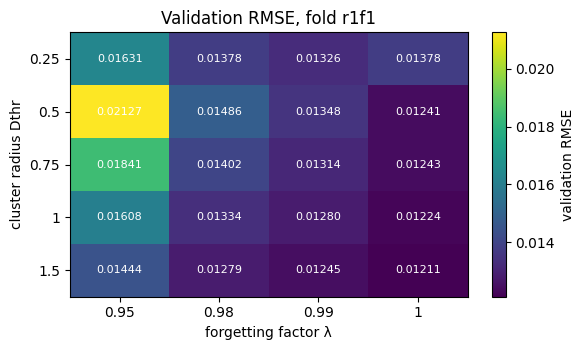

In [27]:
grid_frame = pd.read_csv(RESULTS_DIR / "analysis/validation_grid.csv")

demo_grid = grid_frame[grid_frame["fold_id"] == "r1f1"].pivot(
    index="dthr", columns="lam", values="val_rmse"
)
figure, axis = plt.subplots(figsize=(6.0, 3.6))
image = axis.imshow(demo_grid.to_numpy(), cmap="viridis", aspect="auto")
axis.set_xticks(range(len(demo_grid.columns)))
axis.set_xticklabels([f"{value:g}" for value in demo_grid.columns])
axis.set_yticks(range(len(demo_grid.index)))
axis.set_yticklabels([f"{value:g}" for value in demo_grid.index])
axis.set_xlabel("forgetting factor λ")
axis.set_ylabel("cluster radius Dthr")
axis.set_title("Validation RMSE, fold r1f1")
for i in range(demo_grid.shape[0]):
    for j in range(demo_grid.shape[1]):
        axis.text(j, i, f"{demo_grid.iloc[i, j]:.5f}", ha="center", va="center",
                  color="white", fontsize=8)
figure.colorbar(image, ax=axis, label="validation RMSE")
figure.tight_layout()
plt.show()

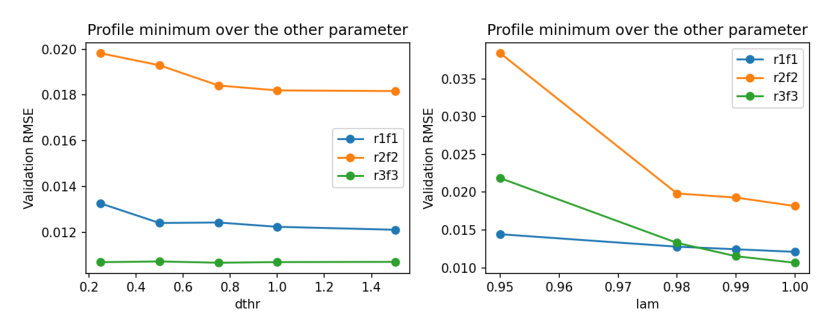

In [28]:
show_png("results/figures/denfis_sensitivity.png", 10.5, 0.42)

### 8.2 Ablations

Two ablations probe whether the two distinctive mechanisms earn their place. Both
are reported as *components of the implementation*, not as causal claims about
the algorithm in general — a caveat that matters for the second one in particular.

* **`no_rls`** replaces the recursive least-squares consequent update with a
  simpler local estimator. It changes the local model *and* its update rule at the
  same time, so it cannot isolate the effect of the forgetting factor alone.
* **`no_merge`** disables rule merging. Most folds never trigger a merge, so this
  ablation is informative mainly on the folds where they do — including `r2f1`,
  which was added specifically because it contains merges.

Four folds are run for each variant (`r1f1`, `r2f1`, `r2f2`, `r3f3`); the table
below is therefore indicative, not a second nine-fold experiment.

In [29]:
ablations = pd.read_csv(RESULTS_DIR / "analysis/ablations.csv")
ablation_table = ablations.pivot_table(index="fold_id", columns="variant",
                                       values=["rmse", "da", "sharpe"])
ablation_table.round({"rmse": 6, "da": 4, "sharpe": 3})

da                                            rmse                                          sharpe                          \
variant denfis_frozen denfis_online  no_merge    no_rls denfis_frozen denfis_online  no_merge    no_rls denfis_frozen denfis_online  no_merge   
fold_id                                                                                                                                         
r1f1         0.500000      0.488000  0.500000  0.524000      0.010635      0.010643  0.010635  0.010544      0.279646      0.260486  0.279646   
r2f1         0.498008      0.486056  0.498008  0.486056      0.018200      0.018824  0.018206  0.018111      1.098048      0.127011  1.059643   
r2f2         0.466403      0.454545  0.466403  0.529644      0.011263      0.011284  0.011263  0.011103     -0.885428     -1.196901 -0.885428   
r3f3         0.539683      0.539683  0.539683  0.559524      0.012019      0.012073  0.012019  0.012087      1.248449      1.152836  1.248449   

                   
variant    no_rls  
fold_id            
r1f1     2.432420  
r2f1     0.223259  
r2f2     1.721666  
r3f3     2.566882

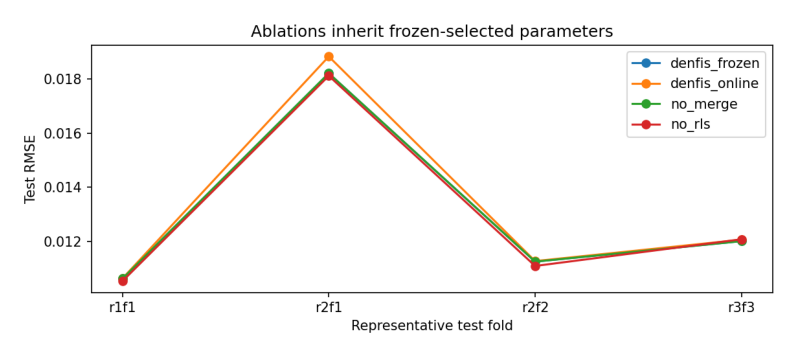

In [30]:
show_png("results/figures/denfis_ablations.png", 10.5, 0.42)

### 8.3 What the rules actually say

Interpretability is the main reason to use a fuzzy rule base here, so it is worth
showing what a fitted model looks like rather than asserting that it is
interpretable.

* The **membership** figure shows each rule's activation across the standardised
  feature space: broad rules dominate most of the input space, narrow ones fire
  only in unusual conditions.
* The **rule evolution** figure shows how the number of rules grows over the test
  year in the online variant. A flat curve means the partition was adequate from
  the start; a rising curve means the model kept discovering new regimes.
* The **contribution** figure decomposes one prediction into its rule terms. It is
  a local, numerical explanation of one forecast — not evidence that the rule is
  economically meaningful.

The chosen case is the largest absolute realised return in fold `r3f3`. It is
selected *after* the fact, purely for illustration, and the model's own prediction
for that day was far too small: this is a case where the model fails, shown
because a failure is more informative than a success.

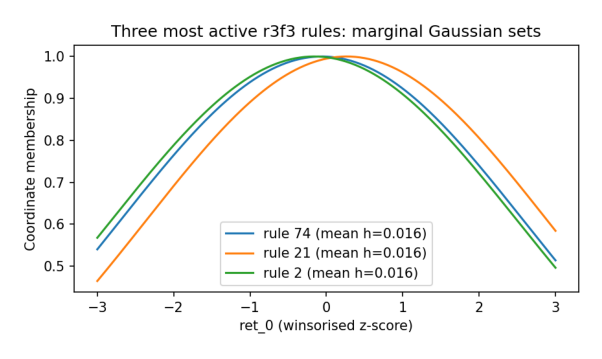

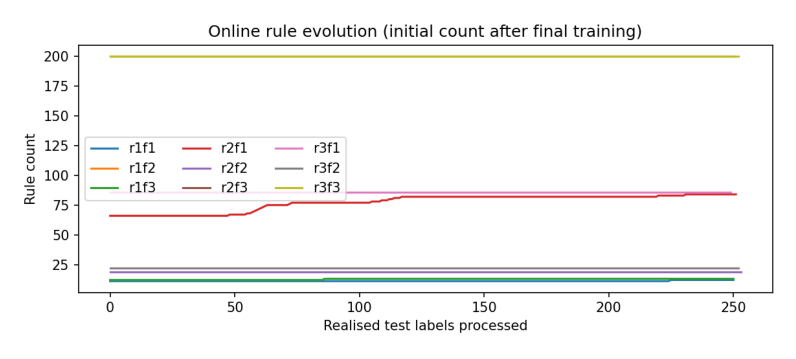

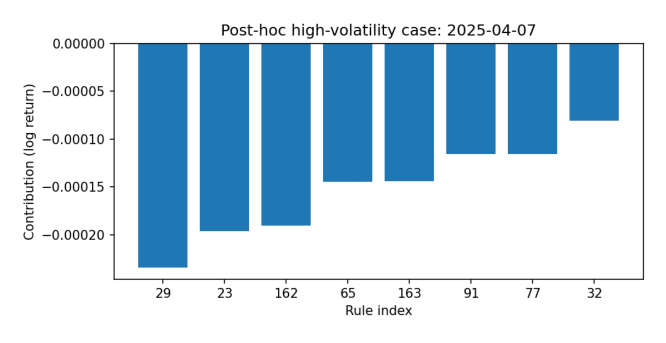

date                                              2025-04-07 00:00:00
realised return                                               -0.0835
model prediction                                              -0.0027
selection rule      largest absolute realised return in r3f3; post...
dtype: object

In [31]:
show_png("results/figures/denfis_memberships.png", 10.5, 0.42)
show_png("results/figures/denfis_rule_evolution.png", 10.5, 0.42)
show_png("results/figures/denfis_case_contributions.png", 10.5, 0.40)

with (RESULTS_DIR / "analysis/high_volatility_case.json").open(encoding="utf-8") as handle:
    case = json.load(handle)
pd.Series({
    "date": case["label_date"],
    "realised return": f"{case['actual']:.4f}",
    "model prediction": f"{case['prediction']:.4f}",
    "selection rule": case["selection"],
})

### 8.4 Transfer from the STI index

A separate, deliberately small experiment asks whether rules learned on the
broader Singapore market transfer to a single bank stock. Three folds and three
protocols are reported in their own directory; **none of these rows enter the
nine-fold main table.**

* **`scratch`** — train on STI, predict DBS, no DBS labels ever used for fitting
  or selection.
* **`zero_shot`** — strict source-only: hyper-parameters and the trading threshold
  are also chosen without DBS labels, using the STI validation year.
* **`fine_tune`** — start from the STI rules, then adapt consequents on DBS
  training data.

Each market is standardised with its own training-only statistics; rules are
matched in standardised space. This is an assumption worth stating explicitly,
because it means a rule centre does not correspond to the same raw price level in
the two markets.

In [32]:
transfer = pd.read_csv(RESULTS_DIR / "transfer/summary.csv")
transfer[["protocol", "fold_id", "test_year", "n", "rmse", "da", "sharpe",
          "n_rules", "test_adaptation"]].sort_values(
    ["protocol", "fold_id"]).set_index(["protocol", "fold_id"]).round(4)

test_year    n    rmse      da  sharpe  n_rules  test_adaptation
protocol  fold_id                                                                  
fine_tune r1f1          2017  250  0.0106  0.4840  0.7298       15            False
          r2f2          2021  253  0.0113  0.4704  0.0474       26            False
          r3f3          2025  252  0.0120  0.4960  1.9845      200            False
scratch   r1f1          2017  250  0.0106  0.5040  1.6395       11            False
          r2f2          2021  253  0.0113  0.4506 -0.8560       19            False
          r3f3          2025  252  0.0120  0.5357  1.2484      200            False
zero_shot r1f1          2017  250  0.0106  0.4800  1.1704       12            False
          r2f2          2021  253  0.0112  0.4387 -0.1288       22            False
          r3f3          2025  252  0.0121  0.4762  1.2315      200            False

### 8.5 Strengths, weaknesses and how this compares to published work

**What this implementation does well.** Six of the nine folds settle between 11 and
86 rules, and on those the rule base is small enough to read: each prediction
decomposes into a handful of local terms, and the model needs no GPU. Its drawdown
is materially lower than both baselines and buy-and-hold, which is consistent with
a model that stays out of the market when its forecast is near zero.

**Where it is weak.** In the three folds that saturate the 200-rule cap, "an
interpretable fuzzy model" is no longer an accurate description of what was fitted
— the cap, not the data, chose the model size. Forecast error is not better than
the baselines, and the
directional accuracy is indistinguishable from 50%. The model's advantage, if any,
is in *when not to trade*, not in knowing which way the price will move. The
online variant adds an update rule that the frozen one lacks, yet it did not
improve results on this run — plausibly because one year of test data is too short
for adaptation to pay for its extra variance.

**How far this is from published work.** The comparison with the literature is
one of scope, not of score. Published evolving-fuzzy systems are often evaluated
on benchmark regression streams or on higher-frequency data where the
signal-to-noise ratio is more favourable. Deep neuro-fuzzy models such as DCNFIS
operate on image data with vastly more structure per example. We deliberately do
not claim that our RMSE or Sharpe is comparable to any number reported in those
papers: different data, different target, different evaluation. What the
literature supplies here is the mechanism (ECM, TSK, RLS) and the caution that
evolving structure is not automatically an advantage.

**The honest summary.** On this task, with these features and this sample,
DENFIS is a competitive and interpretable model, not a superior one. Section 9
lists what would be needed to make the "superior" claim testable.

## 9. Future work

Four directions follow directly from the limitations above, ordered by how much
they would change the conclusion.

1. **More independent test data.** The binding constraint is not model capacity
   but the number of independent years. Extending to other SGX banks, or to a
   panel of similar markets with shared structure, would give the statistical
   tests something to work with. A nine-year single-stock sample cannot resolve a
   Sharpe difference of the size observed here.

2. **A target the model can actually fit.** Next-day returns are close to
   unpredictable with public daily bars. Volatility, drawdown regime, or
   multi-day horizon returns are all plausible targets where local fuzzy rules
   have a structural reason to help, and where RMSE comparisons would be less
   dominated by noise.

3. **Constrained structure for interpretability.** The current cap and merge rule
   are engineering safeguards. A principled complexity penalty — for example one
   that prices a rule in validation-error units — would turn "few rules" from a
   hope into an objective the model is selected on.

4. **Online evaluation with a longer stream.** The frozen/online comparison needs
   more than one test year per fold to estimate the benefit of adaptation.
   Streaming evaluation across the whole out-of-sample period, with a fixed
   adaptation budget, would test the claim that evolving structure pays for its
   variance.

Each of these is a change to the *experiment*, not to the implementation, which is
the right place to spend effort: the code already reproduces its results exactly.

## 10. References

Numbers below are the citation numbering used throughout the repository
(`docs/refs.md`). Claims in this notebook are attributed to the sources listed
here; no result of another study is reproduced.

### Reference register

Verified against author/institutional repositories or publisher records on
2026-11-10. These are related methods, not additional empirical baselines.

| Year | Reference and primary source | Role in this project |
|---|---|---|
| 1993 | J.-S. R. Jang, *ANFIS: Adaptive-Network-Based Fuzzy Inference System*, IEEE TSMC 23(3), 665–685. [Author publications](https://www.cs.nthu.edu.tw/~jang/publication.htm), DOI 10.1109/21.256541 | Adaptive-network fuzzy modelling; contrast fixed structure with evolving rules. |
| 1994 | D. N. Politis and J. P. Romano, *The Stationary Bootstrap*, JASA 89(428), 1303–1313. [Publisher](https://doi.org/10.1080/01621459.1994.10476870) | Dependent-return uncertainty estimation. |
| 1995 | F. X. Diebold and R. S. Mariano, *Comparing Predictive Accuracy*, JBES 13(3), 253–263. [Publisher](https://doi.org/10.1080/07350015.1995.10524599) | Paired forecast-loss comparison. |
| 1997 | S. Hochreiter and J. Schmidhuber, *Long Short-Term Memory*, Neural Computation 9(8), 1735–1780. [Author-hosted paper](https://www.bioinf.jku.at/publications/older/2604.pdf) | Recurrent temporal baseline; not evidence of financial profitability. |
| 2001 | Q. Song and N. Kasabov, *ECM—A Novel On-line, Evolving Clustering Method and Its Applications*. [AUT manuscript](https://kedri.aut.ac.nz/__data/assets/pdf_file/0018/23256/qs2001_36.pdf) | Normalised distance and centre/radius updates. |
| 2002 | N. Kasabov and Q. Song, *DENFIS: Dynamic Evolving Neural-Fuzzy Inference System and Its Application for Time-Series Prediction*, IEEE TFS 10(2), 144–154. [Institutional record](https://pure.ulster.ac.uk/en/publications/denfis-dynamic-evolving-neural-fuzzy-inference-system-and-its-app/), DOI 10.1109/91.995117 | Central established method; our Gaussian/two-pass/bounded variant is explicitly disclosed. |
| 2004 | P. Angelov and D. Filev, *An Approach to Online Identification of Takagi–Sugeno Fuzzy Models*, IEEE TSMC-B 34(1), 484–498. [Lancaster paper](https://eprints.lancs.ac.uk/id/eprint/899/1/SMC-B_paper.pdf) | Related evolving TS identification; not implemented here. |
| 2006 | H.-J. Rong, N. Sundararajan, G.-B. Huang and P. Saratchandran, *Sequential Adaptive Fuzzy Inference System (SAFIS) for Nonlinear System Identification and Prediction*, FSS 157, 1260–1275. [Publisher](https://doi.org/10.1016/j.fss.2005.12.011) | Rule influence and structural adaptation. Workplan's 2008 date is corrected to 2006. |
| 2014 | M. Pratama, S. G. Anavatti, P. Angelov and E. Lughofer, *PANFIS: A Novel Incremental Learning Machine*, IEEE TNNLS 25(1), 55–68. [Lancaster record](https://www.research.lancs.ac.uk/portal/en/publications/panfis(5750842e-9605-4058-90d6-079338408a32)/export.html), DOI 10.1109/TNNLS.2013.2271933 | Related incremental fuzzy architecture; no direct benchmark claim. |
| 2016 | T. Chen and C. Guestrin, *XGBoost: A Scalable Tree Boosting System*, KDD, 785–794. [Authors' preprint](https://arxiv.org/abs/1603.02754) | Regularised tree baseline. |
| 2023 | M. Yeganejou, K. Honari, R. Kluzinski, S. Dick, M. Lipsett and J. Miller, *DCNFIS: Deep Convolutional Neuro-Fuzzy Inference System*. [Authors' preprint](https://arxiv.org/abs/2308.06378) | Deep visual fuzzy modelling as a future direction, not a stock-return benchmark. |
| 2024 | M. Alateeq and W. Pedrycz, *Logic-oriented fuzzy neural networks: A survey*, Expert Systems with Applications 257, 125120, DOI 10.1016/j.eswa.2024.125120. [Publisher](https://www.sciencedirect.com/science/article/pii/S0957417424019870) | Modern review context, distinct from our empirical stock-return task. |

Do not claim state-of-the-art stock prediction from these citations. Only XGBoost
and LSTM are empirically compared under this repository's folds. Final reference numbering belongs to notebook integration.

## Appendix — complete implementation

The DENFIS model itself is inlined in Section 5.5. The remaining modules that
produce the numbers in this report are listed here in full, so the notebook is
self-contained as a record of the method even without the repository.

Every listing below is the exact file content at the git commit printed in
Section 1.

**`src/data.py`**

```python
"""Data download, cleaning, caching, and loading.

Primary source is the Yahoo Finance chart endpoint, which returns the same
daily OHLCV and adjusted-close series as yfinance but without the library's
rate-limit wrapper.  The final notebook only reads the cached CSVs written by
this module; it never needs network access.

Protocol notes
--------------
* D05.SI: rows with missing OHLC/adj-close or Volume <= 0 are dropped.
* ^STI is an index: its volume is frequently zero, so the volume filter does
  not apply.  Missing volume is stored as 0 and price rows are kept.  The
  transfer-learning report documents that index volume is not informative.
"""

from __future__ import annotations

import hashlib
import json
import time
from datetime import datetime, timezone
from pathlib import Path
from typing import Optional
from zoneinfo import ZoneInfo

import pandas as pd
import requests

try:  # allow `python src/data.py` as well as `python -m src.data`
    from config import (
        DATA_DIR,
        DATE_COL,
        END_DATE,
        PRICE_COLS,
        START_DATE,
        SYMBOL_DBS,
        SYMBOL_STI,
    )
except ImportError:  # pragma: no cover - direct script execution
    import sys

    sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
    from config import (  # type: ignore
        DATA_DIR,
        DATE_COL,
        END_DATE,
        PRICE_COLS,
        START_DATE,
        SYMBOL_DBS,
        SYMBOL_STI,
    )

CHART_URL = "https://query1.finance.yahoo.com/v8/finance/chart/{symbol}"
HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/124.0 Safari/537.36"
    )
}
SG_TZ = ZoneInfo("Asia/Singapore")


def _epoch(date_str: str) -> int:
    """UTC midnight for a YYYY-MM-DD date, as a Unix timestamp."""
    return int(pd.Timestamp(date_str, tz="UTC").timestamp())


def _to_sg_date(ts: int) -> str:
    return (
        datetime.fromtimestamp(ts, tz=timezone.utc)
        .astimezone(SG_TZ)
        .date()
        .isoformat()
    )


def download_prices(
    symbol: str,
    start: str = START_DATE,
    end: str = END_DATE,
    retries: int = 4,
    pause: float = 3.0,
) -> pd.DataFrame:
    """Download daily bars for one symbol and return a raw DataFrame.

    `end` is inclusive: the request asks for one extra day so that a bar
    stamped at the end date is returned.
    """
    params = {
        "period1": _epoch(start),
        "period2": _epoch(end) + 86400,
        "interval": "1d",
        "events": "div,splits",
    }
    url = CHART_URL.format(symbol=requests.utils.quote(symbol, safe=""))

    last_error: Optional[Exception] = None
    for attempt in range(retries):
        try:
            response = requests.get(url, params=params, headers=HEADERS, timeout=30)
            if response.status_code == 429:
                raise RuntimeError("Yahoo returned 429 (rate limited)")
            response.raise_for_status()
            payload = response.json()
            chart = payload.get("chart") or {}
            if chart.get("error"):
                raise RuntimeError(f"Yahoo chart error: {chart['error']}")
            result = chart["result"][0]
            break
        except Exception as exc:  # noqa: BLE001 - retry any transient failure
            last_error = exc
            if attempt == retries - 1:
                raise RuntimeError(
                    f"Failed to download {symbol} after {retries} attempts: {exc}"
                ) from exc
            time.sleep(pause * (2**attempt))
    else:  # pragma: no cover - defensive
        raise RuntimeError(f"Failed to download {symbol}: {last_error}")

    timestamps = result.get("timestamp") or []
    quote = result["indicators"]["quote"][0]
    adjclose_block = result["indicators"].get("adjclose")
    adjclose = (
        adjclose_block[0]["adjclose"]
        if adjclose_block
        else quote.get("close")
    )

    if len(timestamps) != len(quote["close"]) or len(timestamps) != len(adjclose):
        raise ValueError(f"Inconsistent arrays for {symbol}")

    df = pd.DataFrame(
        {
            DATE_COL: [_to_sg_date(ts) for ts in timestamps],
            "Open": quote.get("open"),
            "High": quote.get("high"),
            "Low": quote.get("low"),
            "Close": quote.get("close"),
            "Adj Close": adjclose,
            "Volume": quote.get("volume"),
        }
    )
    return df


def clean_prices(df: pd.DataFrame, is_index: bool = False) -> pd.DataFrame:
    """Apply the protocol's cleaning rules and return a sorted DataFrame."""
    out = df.copy()
    out[DATE_COL] = pd.to_datetime(out[DATE_COL]).dt.date
    out = out.sort_values(DATE_COL).drop_duplicates(DATE_COL, keep="last")

    for col in ["Open", "High", "Low", "Close", "Adj Close"]:
        out[col] = pd.to_numeric(out[col], errors="coerce")
    out["Volume"] = pd.to_numeric(out["Volume"], errors="coerce")

    out = out.replace([float("inf"), float("-inf")], pd.NA)
    out = out.dropna(subset=["Open", "High", "Low", "Close", "Adj Close"])

    if is_index:
        out["Volume"] = out["Volume"].fillna(0.0)
    else:
        out = out[out["Volume"].fillna(0.0) > 0]

    return out.reset_index(drop=True)


def save_cache(df: pd.DataFrame, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False, date_format="%Y-%m-%d")


def load_prices(name: str) -> pd.DataFrame:
    """Load a cached file by name: 'D05_SI' or 'STI'."""
    path = DATA_DIR / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run `python -m src.data` to download and cache data."
        )
    df = pd.read_csv(path, parse_dates=[DATE_COL])
    df[DATE_COL] = df[DATE_COL].dt.date
    return df


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def write_checksums(paths: list[Path], out_path: Path) -> dict[str, str]:
    checksums = {p.name: sha256_file(p) for p in paths}
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with out_path.open("w", encoding="utf-8") as handle:
        for name, digest in checksums.items():
            handle.write(f"{digest}  {name}\n")
    return checksums


def download_all() -> dict:
    """Download both series, clean, cache, and write checksums + metadata."""
    specs = [
        ("D05_SI", SYMBOL_DBS, False),
        ("STI", SYMBOL_STI, True),
    ]
    summary: dict[str, dict] = {}
    written: list[Path] = []

    for name, symbol, is_index in specs:
        raw = download_prices(symbol)
        clean = clean_prices(raw, is_index=is_index)
        path = DATA_DIR / f"{name}.csv"
        save_cache(clean, path)
        written.append(path)
        summary[name] = {
            "symbol": symbol,
            "rows": int(len(clean)),
            "first_date": str(clean[DATE_COL].iloc[0]),
            "last_date": str(clean[DATE_COL].iloc[-1]),
            "is_index": is_index,
        }
        print(
            f"{name:7s} {symbol:8s} rows={len(clean):5d}  "
            f"{clean[DATE_COL].iloc[0]} .. {clean[DATE_COL].iloc[-1]}"
        )

    checksums = write_checksums(written, DATA_DIR / "checksums.txt")
    metadata = {
        "source": "Yahoo Finance chart API",
        "downloaded_at": datetime.now(timezone.utc).isoformat(),
        "start": START_DATE,
        "end": END_DATE,
        "series": summary,
        "sha256": checksums,
    }
    meta_path = DATA_DIR / "metadata.json"
    with meta_path.open("w", encoding="utf-8") as handle:
        json.dump(metadata, handle, indent=2, ensure_ascii=False)
    print(f"Wrote {meta_path}")
    return metadata


if __name__ == "__main__":
    download_all()
```

**`src/features.py`**

```python
"""Causal feature engineering for the 13 frozen protocol features.

The output frame carries ``Date`` (feature date), ``label_date`` (the trading
day whose return is predicted), the 13 features, and ``y`` (next-day log
return).  Folds are assigned by ``label_date`` so that a test year contains
returns realised inside that year, not features stamped inside it.
"""

from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd

from config import (
    DATE_COL,
    FEATURE_WARMUP,
    FEATURES,
    TARGET_COL,
)


def _rsi(price: pd.Series, window: int = 14) -> pd.Series:
    """Wilder's RSI, returning values in [0, 100]."""
    delta = price.diff()
    gain = delta.clip(lower=0.0)
    loss = -delta.clip(upper=0.0)

    avg_gain = gain.ewm(alpha=1.0 / window, adjust=False, min_periods=window).mean()
    avg_loss = loss.ewm(alpha=1.0 / window, adjust=False, min_periods=window).mean()

    rs = avg_gain / avg_loss.replace(0.0, np.nan)
    rsi = 100.0 - 100.0 / (1.0 + rs)
    rsi = rsi.where(avg_loss != 0.0, 100.0)
    rsi = rsi.where(~((avg_gain == 0.0) & (avg_loss == 0.0)), 50.0)
    return rsi


def compute_features(prices: pd.DataFrame) -> pd.DataFrame:
    """Build the protocol's 13 features and next-day log-return label.

    Parameters
    ----------
    prices : DataFrame
        Cleaned daily bars with Date, Open, High, Low, Close, Adj Close, Volume.
    """
    out = prices.copy()
    out[DATE_COL] = pd.to_datetime(out[DATE_COL])
    out = out.sort_values(DATE_COL).drop_duplicates(DATE_COL, keep="last")
    out = out.reset_index(drop=True)

    price = out["Adj Close"].astype(float)
    volume = out["Volume"].astype(float)
    ret = np.log(price / price.shift(1))

    out["ret_0"] = ret
    for lag in range(1, 5):
        out[f"ret_{lag}"] = ret.shift(lag)

    for window in (5, 20, 60):
        out[f"ma{window}"] = price / price.rolling(window).mean() - 1.0

    out["rsi14"] = (_rsi(price) - 50.0) / 50.0

    ema12 = price.ewm(span=12, adjust=False).mean()
    ema26 = price.ewm(span=26, adjust=False).mean()
    macd_line = ema12 - ema26
    signal_line = macd_line.ewm(span=9, adjust=False).mean()
    out["macd"] = (macd_line - signal_line) / price

    ma20 = price.rolling(20).mean()
    sd20 = price.rolling(20).std(ddof=0)
    upper = ma20 + 2.0 * sd20
    lower = ma20 - 2.0 * sd20
    width = upper - lower
    boll = (price - lower) / width
    out["boll_b"] = boll.where(width.abs() > 1e-12, 0.5)

    out["rv20"] = ret.rolling(20).std(ddof=1) * np.sqrt(252.0)

    vol_mean = volume.rolling(20).mean()
    vol_std = volume.rolling(20).std(ddof=1)
    vol_z = (volume - vol_mean) / vol_std.replace(0.0, np.nan)
    out["vol_z"] = vol_z.fillna(0.0)

    out[TARGET_COL] = ret.shift(-1)
    out["label_date"] = out[DATE_COL].shift(-1)

    # Drop the warmup block, then any row that is still undefined.
    out = out.iloc[FEATURE_WARMUP:].copy()
    out = out.dropna(subset=FEATURES + [TARGET_COL, "label_date"])

    return out[[DATE_COL, "label_date"] + FEATURES + [TARGET_COL]].reset_index(drop=True)


def to_xy(frame: pd.DataFrame):
    """Return positional arrays plus date indexers from a feature frame."""
    X = frame[FEATURES].to_numpy(dtype=np.float64)
    y = frame[TARGET_COL].to_numpy(dtype=np.float64)
    dates = pd.to_datetime(frame[DATE_COL])
    label_dates = pd.to_datetime(frame["label_date"])
    return X, y, dates, label_dates


@dataclass(frozen=True)
class FeatureScaler:
    """Per-fold winsorisation and standardisation parameters."""

    lower: pd.Series
    upper: pd.Series
    mean: pd.Series
    std: pd.Series


def fit_scaler(
    X: pd.DataFrame,
    lower_q: float = 0.005,
    upper_q: float = 0.995,
) -> FeatureScaler:
    """Fit winsorisation bounds and z-score statistics on training rows only."""
    lower = X.quantile(lower_q)
    upper = X.quantile(upper_q)
    clipped = X.clip(lower, upper, axis=1)
    mean = clipped.mean()
    std = clipped.std(ddof=1).replace(0.0, 1.0)
    return FeatureScaler(lower=lower, upper=upper, mean=mean, std=std)


def transform_scaler(X: pd.DataFrame, scaler: FeatureScaler) -> np.ndarray:
    """Apply a fitted scaler and return a float64 array in FEATURES order."""
    clipped = X.clip(scaler.lower, scaler.upper, axis=1)
    scaled = (clipped - scaler.mean) / scaler.std
    return scaled.to_numpy(dtype=np.float64)


def scale_fold(
    frame: pd.DataFrame,
    train_idx: np.ndarray,
    other_indices: dict[str, np.ndarray],
) -> tuple[dict[str, np.ndarray], FeatureScaler]:
    """Fit on train_idx and transform every requested index set."""
    train_X = frame.iloc[train_idx][FEATURES]
    scaler = fit_scaler(train_X)
    transformed = {
        name: transform_scaler(frame.iloc[idx][FEATURES], scaler)
        for name, idx in other_indices.items()
    }
    return transformed, scaler
```

**`src/splits.py`**

```python
"""Expanding walk-forward folds with label-date purging.

Each row's label is the next trading day's return, so folds are assigned by
``label_date`` rather than by the feature date.  This guarantees that a test
year contains exactly the returns realised inside that year, and that no
training label ever reaches into a validation or test period.
"""

from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd

from config import FOLD_SPECS, HOLDOUT_SPEC


@dataclass(frozen=True)
class Fold:
    fold_id: str
    rep: int
    fold: int
    test_year: int | None
    select_train_idx: np.ndarray
    val_idx: np.ndarray
    train_idx: np.ndarray
    test_idx: np.ndarray
    select_train_end: pd.Timestamp
    final_train_end: pd.Timestamp
    val_start: pd.Timestamp
    val_end: pd.Timestamp
    test_start: pd.Timestamp
    test_end: pd.Timestamp


def _idx(mask: np.ndarray) -> np.ndarray:
    return np.flatnonzero(np.asarray(mask, dtype=bool))


def _windows_for_year(test_year: int) -> dict[str, pd.Timestamp]:
    return {
        "select_train_end": pd.Timestamp(f"{test_year - 2}-12-31"),
        "val_start": pd.Timestamp(f"{test_year - 1}-01-01"),
        "val_end": pd.Timestamp(f"{test_year - 1}-12-31"),
        "final_train_end": pd.Timestamp(f"{test_year - 1}-12-31"),
        "test_start": pd.Timestamp(f"{test_year}-01-01"),
        "test_end": pd.Timestamp(f"{test_year}-12-31"),
    }


def _build_fold(
    label_dates: pd.DatetimeIndex,
    *,
    fold_id: str,
    rep: int,
    fold: int,
    test_year: int | None,
    windows: dict[str, pd.Timestamp],
) -> Fold:
    select_train_idx = _idx(label_dates <= windows["select_train_end"])
    val_idx = _idx(
        (label_dates >= windows["val_start"]) & (label_dates <= windows["val_end"])
    )
    train_idx = _idx(label_dates <= windows["final_train_end"])
    test_idx = _idx(
        (label_dates >= windows["test_start"]) & (label_dates <= windows["test_end"])
    )

    for name, idx in [
        ("select_train", select_train_idx),
        ("val", val_idx),
        ("train", train_idx),
        ("test", test_idx),
    ]:
        if len(idx) == 0:
            raise ValueError(f"{fold_id}: empty {name} index set")

    # Structural guarantees: no training label reaches validation or test.
    if label_dates[select_train_idx].max() >= windows["val_start"]:
        raise AssertionError(f"{fold_id}: selection train leaks into validation")
    if label_dates[val_idx].max() >= windows["test_start"]:
        raise AssertionError(f"{fold_id}: validation leaks into test")
    if label_dates[train_idx].max() >= windows["test_start"]:
        raise AssertionError(f"{fold_id}: final train leaks into test")
    if len(np.intersect1d(train_idx, test_idx)):
        raise AssertionError(f"{fold_id}: train/test overlap")

    return Fold(
        fold_id=fold_id,
        rep=rep,
        fold=fold,
        test_year=test_year,
        select_train_idx=select_train_idx,
        val_idx=val_idx,
        train_idx=train_idx,
        test_idx=test_idx,
        **windows,
    )


def make_folds(
    label_dates,
    specs: list[dict] | None = None,
    holdout: dict | None = None,
) -> list[Fold]:
    """Build nine regular folds plus the 2026 holdout."""
    specs = FOLD_SPECS if specs is None else specs
    holdout = HOLDOUT_SPEC if holdout is None else holdout
    label_dates = pd.DatetimeIndex(pd.to_datetime(label_dates))

    folds: list[Fold] = []
    for spec in specs:
        windows = _windows_for_year(int(spec["test_year"]))
        folds.append(
            _build_fold(
                label_dates,
                fold_id=str(spec["fold_id"]),
                rep=int(spec["rep"]),
                fold=int(spec["fold"]),
                test_year=int(spec["test_year"]),
                windows=windows,
            )
        )

    holdout_windows = {
        "select_train_end": pd.Timestamp(holdout["select_train_end"]),
        "val_start": pd.Timestamp(holdout["val_start"]),
        "val_end": pd.Timestamp(holdout["val_end"]),
        "final_train_end": pd.Timestamp(holdout["final_train_end"]),
        "test_start": pd.Timestamp(holdout["test_start"]),
        "test_end": pd.Timestamp(holdout["test_end"]),
    }
    folds.append(
        _build_fold(
            label_dates,
            fold_id=str(holdout["fold_id"]),
            rep=int(holdout["rep"]),
            fold=int(holdout["fold"]),
            test_year=None,
            windows=holdout_windows,
        )
    )
    return folds


def make_folds_from_frame(frame: pd.DataFrame) -> list[Fold]:
    """Convenience wrapper for a feature frame produced by compute_features."""
    return make_folds(pd.to_datetime(frame["label_date"]))


def fold_summary(folds: list[Fold], label_dates) -> pd.DataFrame:
    """Human-readable table used in the notebook and in tests."""
    label_dates = pd.DatetimeIndex(pd.to_datetime(label_dates))
    rows = []
    for fold in folds:
        rows.append(
            {
                "fold_id": fold.fold_id,
                "rep": fold.rep,
                "fold": fold.fold,
                "test_year": fold.test_year,
                "n_select_train": len(fold.select_train_idx),
                "n_val": len(fold.val_idx),
                "n_train": len(fold.train_idx),
                "n_test": len(fold.test_idx),
                "first_test_label": label_dates[fold.test_idx].min().date(),
                "last_test_label": label_dates[fold.test_idx].max().date(),
            }
        )
    return pd.DataFrame(rows)


def get_fold(folds: list[Fold], fold_id: str) -> Fold:
    for fold in folds:
        if fold.fold_id == fold_id:
            return fold
    raise KeyError(f"Unknown fold_id: {fold_id}")
```

**`src/models/baselines.py`**

```python
"""Benchmark models.

XGBoost is implemented first because it validates the CV runner end to end.
The LSTM is added to this module once the sequence plumbing is in place.
"""

from __future__ import annotations

import copy
from typing import Optional

import numpy as np
import torch
import torch.nn as nn
from xgboost import XGBRegressor

from config import GLOBAL_SEED


class NaiveZeroModel:
    """The no-prediction baseline: forecast no change.

    The target is a log return, so ``y_pred = 0`` means "tomorrow's adjusted
    close equals today's".  This is the random-walk forecast the instructor
    asked every model to be compared against; it is fitted-free and
    deterministic, so it is a valid member of the CV runner's model registry.
    """

    name = "no_prediction"

    def __init__(self, params: Optional[dict] = None, seed: int = GLOBAL_SEED):
        self.params = dict(params or {})
        self.seed = seed
        self.n_features_in_: Optional[int] = None

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        X = np.asarray(X)
        if X.ndim not in (2, 3):
            raise ValueError(f"expected a 2-D or 3-D input, got {X.shape}")
        if len(X) != len(y):
            raise ValueError(f"X/y length mismatch: {len(X)} vs {len(y)}")
        self.n_features_in_ = int(X.shape[-1])

    def predict(self, X: np.ndarray) -> np.ndarray:
        X = np.asarray(X)
        if X.ndim not in (2, 3):
            raise ValueError(f"expected a 2-D or 3-D input, got {X.shape}")
        return np.zeros(len(X), dtype=np.float64)

    def partial_fit(self, x: np.ndarray, y: float) -> None:
        """The forecast never changes, so online updates are no-ops."""
        return None


class XGBModel:
    """XGBoost regressor with the protocol's fixed search space."""

    name = "xgboost"

    def __init__(self, params: Optional[dict] = None, seed: int = GLOBAL_SEED):
        self.params = dict(params or {})
        self.seed = seed
        self.model: Optional[XGBRegressor] = None
        self.best_iteration_: Optional[int] = None

    def _build(self, n_estimators: int, early_stopping: bool) -> XGBRegressor:
        kwargs = dict(
            n_estimators=int(n_estimators),
            max_depth=int(self.params.get("max_depth", 2)),
            learning_rate=float(self.params.get("learning_rate", 0.03)),
            subsample=float(self.params.get("subsample", 0.8)),
            colsample_bytree=float(self.params.get("colsample_bytree", 0.8)),
            min_child_weight=float(self.params.get("min_child_weight", 5)),
            reg_lambda=float(self.params.get("reg_lambda", 1.0)),
            objective="reg:squarederror",
            tree_method="hist",
            random_state=self.seed,
            n_jobs=1,
        )
        if early_stopping:
            kwargs["early_stopping_rounds"] = 50
        return XGBRegressor(**kwargs)

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        n_estimators = int(self.params.get("n_estimators", 500))
        if self.best_iteration_ is not None:
            n_estimators = self.best_iteration_ + 1
        self.model = self._build(n_estimators, early_stopping=False)
        self.model.fit(X, y, verbose=False)

    def fit_with_validation(
        self,
        X: np.ndarray,
        y: np.ndarray,
        X_val: np.ndarray,
        y_val: np.ndarray,
    ) -> None:
        self.model = self._build(1000, early_stopping=True)
        self.model.fit(
            X,
            y,
            eval_set=[(X_val, y_val)],
            verbose=False,
        )
        best = getattr(self.model, "best_iteration", None)
        self.best_iteration_ = int(best) if best is not None else None

    def predict(self, X: np.ndarray) -> np.ndarray:
        if self.model is None:
            raise RuntimeError("XGBModel.predict called before fit")
        return np.asarray(self.model.predict(X), dtype=np.float64)


class _LSTMRegressor(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, dropout: float):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        output, _ = self.lstm(x)
        last = output[:, -1, :]
        return self.head(self.dropout(last)).squeeze(-1)


class LSTMModel:
    """Small CPU LSTM over 20-day sequences of the same 13 features.

    ``fit`` expects a 3-D array ``(n, seq_len, n_features)``.  The CV runner
    builds those sequences with context from earlier rows, so a test sequence
    never sees future prices.
    """

    name = "lstm"
    requires_sequence = True

    def __init__(self, params: Optional[dict] = None, seed: int = GLOBAL_SEED):
        self.params = dict(params or {})
        self.seed = seed
        self.seq_len = int(self.params.get("seq_len", 20))
        self.hidden_size = int(self.params.get("hidden_size", 32))
        self.dropout = float(self.params.get("dropout", 0.1))
        self.epochs = int(self.params.get("epochs", 100))
        self.patience = int(self.params.get("patience", 15))
        self.batch_size = int(self.params.get("batch_size", 64))
        self.lr = float(self.params.get("lr", 1e-3))
        self.weight_decay = float(self.params.get("weight_decay", 1e-4))
        self.model: Optional[_LSTMRegressor] = None
        self.best_epoch_: Optional[int] = None

    def _score(self, X: torch.Tensor, y: np.ndarray) -> float:
        self.model.eval()
        with torch.no_grad():
            pred = self.model(X).cpu().numpy()
        return float(np.sqrt(np.mean((y - pred) ** 2)))

    def _fit(
        self,
        X: np.ndarray,
        y: np.ndarray,
        X_val: Optional[np.ndarray] = None,
        y_val: Optional[np.ndarray] = None,
        max_epochs: Optional[int] = None,
    ) -> None:
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)
        if X.ndim != 3:
            raise ValueError(f"LSTM expects (n, seq_len, features), got {X.shape}")
        if len(X) != len(y):
            raise ValueError(f"X/y length mismatch: {len(X)} vs {len(y)}")
        if len(X) == 0:
            raise ValueError("empty training set")

        max_epochs = self.epochs if max_epochs is None else int(max_epochs)
        torch.manual_seed(self.seed)
        torch.set_num_threads(1)
        try:
            torch.use_deterministic_algorithms(True, warn_only=True)
        except TypeError:  # older torch
            torch.use_deterministic_algorithms(True)

        self.model = _LSTMRegressor(X.shape[2], self.hidden_size, self.dropout)
        optimizer = torch.optim.Adam(
            self.model.parameters(), lr=self.lr, weight_decay=self.weight_decay
        )
        loss_fn = nn.MSELoss()

        X_t = torch.from_numpy(X)
        y_t = torch.from_numpy(y)
        use_validation = X_val is not None and y_val is not None
        if use_validation:
            X_val_t = torch.from_numpy(np.asarray(X_val, dtype=np.float32))
            y_val_np = np.asarray(y_val, dtype=np.float32)

        best_state = None
        best_val = np.inf
        best_epoch = -1
        wait = 0

        for epoch in range(max_epochs):
            self.model.train()
            generator = torch.Generator().manual_seed(self.seed + epoch)
            perm = torch.randperm(len(X_t), generator=generator)
            for start in range(0, len(X_t), self.batch_size):
                batch_idx = perm[start : start + self.batch_size]
                optimizer.zero_grad(set_to_none=True)
                pred = self.model(X_t[batch_idx])
                loss = loss_fn(pred, y_t[batch_idx])
                loss.backward()
                optimizer.step()

            if use_validation:
                val_rmse = self._score(X_val_t, y_val_np)
                if val_rmse < best_val - 1e-12:
                    best_val = val_rmse
                    best_state = copy.deepcopy(self.model.state_dict())
                    best_epoch = epoch
                    wait = 0
                else:
                    wait += 1
                    if wait >= self.patience:
                        break

        if use_validation and best_state is not None:
            self.model.load_state_dict(best_state)
            self.best_epoch_ = int(best_epoch) + 1

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        epochs = self.best_epoch_ if self.best_epoch_ is not None else self.epochs
        self._fit(X, y, max_epochs=epochs)

    def fit_with_validation(
        self,
        X: np.ndarray,
        y: np.ndarray,
        X_val: np.ndarray,
        y_val: np.ndarray,
    ) -> None:
        self._fit(X, y, X_val=X_val, y_val=y_val, max_epochs=self.epochs)

    def predict(self, X: np.ndarray) -> np.ndarray:
        if self.model is None:
            raise RuntimeError("LSTMModel.predict called before fit")
        X = np.asarray(X, dtype=np.float32)
        self.model.eval()
        chunks = []
        with torch.no_grad():
            for start in range(0, len(X), 256):
                chunks.append(self.model(torch.from_numpy(X[start : start + 256])).cpu().numpy())
        return np.concatenate(chunks).astype(np.float64)
```

**`src/evaluation/metrics.py`**

```python
"""Regression and directional metrics on log-return predictions."""

from __future__ import annotations

import numpy as np

from config import DEADBAND


def _pair(y_true, y_pred) -> tuple[np.ndarray, np.ndarray]:
    y_true = np.asarray(y_true, dtype=np.float64).ravel()
    y_pred = np.asarray(y_pred, dtype=np.float64).ravel()
    if y_true.shape != y_pred.shape:
        raise ValueError(f"shape mismatch: {y_true.shape} vs {y_pred.shape}")
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[mask], y_pred[mask]
    if y_true.size == 0:
        raise ValueError("no finite prediction pairs")
    return y_true, y_pred


def rmse(y_true, y_pred) -> float:
    yt, yp = _pair(y_true, y_pred)
    return float(np.sqrt(np.mean((yt - yp) ** 2)))


def mae(y_true, y_pred) -> float:
    yt, yp = _pair(y_true, y_pred)
    return float(np.mean(np.abs(yt - yp)))


def r2(y_true, y_pred) -> float:
    yt, yp = _pair(y_true, y_pred)
    sst = float(np.sum((yt - yt.mean()) ** 2))
    if sst == 0.0:
        return 0.0
    sse = float(np.sum((yt - yp) ** 2))
    return float(1.0 - sse / sst)


def information_coefficient(y_true, y_pred) -> float:
    """Pearson correlation between prediction and realised return."""
    yt, yp = _pair(y_true, y_pred)
    if yt.std(ddof=0) == 0.0 or yp.std(ddof=0) == 0.0:
        return 0.0
    return float(np.corrcoef(yt, yp)[0, 1])


def directional_accuracy(y_true, y_pred, deadband: float = 0.0) -> float:
    """Share of days whose predicted and realised signs agree.

    ``sign(0) == 0``.  With ``deadband > 0``, days with ``|y_true|`` below the
    deadband are excluded (the 5 bp version reported in the protocol).
    """
    yt, yp = _pair(y_true, y_pred)
    if deadband > 0:
        keep = np.abs(yt) >= deadband
        yt, yp = yt[keep], yp[keep]
        if yt.size == 0:
            return float("nan")
    return float(np.mean(np.sign(yt) == np.sign(yp)))


def zero_baseline_metrics(y_true) -> dict[str, float]:
    """Metrics of the no-prediction forecast ``y_pred = 0``.

    In return space this is the random-walk forecast: the price is assumed to
    stay at its last observed value.  Its RMSE is ``sqrt(mean(y**2))`` and its
    MAE is ``mean(|y|)``; every model's skill is measured against these.
    """
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    yt = yt[np.isfinite(yt)]
    if yt.size == 0:
        raise ValueError("no finite targets")
    return {
        "rmse_zero": float(np.sqrt(np.mean(yt**2))),
        "mae_zero": float(np.mean(np.abs(yt))),
    }


def rmse_skill(y_true, y_pred) -> float:
    """Relative RMSE improvement over the no-prediction forecast.

    ``skill = 1 - RMSE(model) / RMSE(zeros)``.  Positive means the model
    beats "predict no change"; negative means it is worse.
    """
    yt, yp = _pair(y_true, y_pred)
    baseline = float(np.sqrt(np.mean(yt**2)))
    if baseline == 0.0:
        return float("nan")
    return float(1.0 - np.sqrt(np.mean((yt - yp) ** 2)) / baseline)


def mae_skill(y_true, y_pred) -> float:
    """Relative MAE improvement over the no-prediction forecast."""
    yt, yp = _pair(y_true, y_pred)
    baseline = float(np.mean(np.abs(yt)))
    if baseline == 0.0:
        return float("nan")
    return float(1.0 - np.mean(np.abs(yt - yp)) / baseline)


def r2_zero(y_true, y_pred) -> float:
    """Coefficient of determination against the no-prediction forecast.

    ``1 - SSE(model) / SSE(zeros)``; zero means the model ties the random
    walk, negative means it is worse.
    """
    yt, yp = _pair(y_true, y_pred)
    sse_zero = float(np.sum(yt**2))
    if sse_zero == 0.0:
        return float("nan")
    return float(1.0 - np.sum((yt - yp) ** 2) / sse_zero)


def compute_metrics(y_true, y_pred) -> dict[str, float]:
    yt, yp = _pair(y_true, y_pred)
    baseline = zero_baseline_metrics(yt)
    metrics = {
        "n": int(yt.size),
        "rmse": rmse(yt, yp),
        "mae": mae(yt, yp),
        "r2": r2(yt, yp),
        "ic": information_coefficient(yt, yp),
        "da": directional_accuracy(yt, yp),
        "da5": directional_accuracy(yt, yp, deadband=DEADBAND),
        "rmse_zero": baseline["rmse_zero"],
        "mae_zero": baseline["mae_zero"],
        "rmse_skill": rmse_skill(yt, yp),
        "mae_skill": mae_skill(yt, yp),
        "r2_zero": r2_zero(yt, yp),
    }
    return metrics
```

**`src/evaluation/backtest.py`**

```python
"""Long/flat backtest on simple returns, with costs and threshold selection.

Predictions and ``y_true`` live in log-return units.  The backtest converts
realised log returns to simple returns before compounding, so the equity curve
is financially correct.  Cost is charged on absolute position changes.
"""

from __future__ import annotations

import numpy as np
import pandas as pd

from config import ANNUALIZATION, COST_BPS, TAU_GRID


def log_to_simple(log_returns) -> np.ndarray:
    return np.expm1(np.asarray(log_returns, dtype=np.float64).ravel())


def make_signal(y_pred, tau: float) -> np.ndarray:
    y_pred = np.asarray(y_pred, dtype=np.float64).ravel()
    return (y_pred > tau).astype(np.int64)


def run_backtest(
    signal,
    simple_returns,
    cost_bps: float = COST_BPS,
) -> pd.DataFrame:
    """Return per-day signal, turnover, strategy return, and benchmark return."""
    signal = np.asarray(signal, dtype=np.int64).ravel()
    simple_returns = np.asarray(simple_returns, dtype=np.float64).ravel()
    if signal.shape != simple_returns.shape:
        raise ValueError(
            f"shape mismatch: signal {signal.shape} vs returns {simple_returns.shape}"
        )

    prev = np.concatenate([[0], signal[:-1]])
    turnover = np.abs(signal - prev).astype(np.float64)
    cost = (cost_bps / 10_000.0) * turnover
    strat_ret = signal * simple_returns - cost

    return pd.DataFrame(
        {
            "signal": signal,
            "position": signal,
            "turnover": turnover,
            "strat_ret": strat_ret,
            "bench_ret": simple_returns,
        }
    )


def equity_curve(returns) -> np.ndarray:
    returns = np.asarray(returns, dtype=np.float64).ravel()
    return np.concatenate([[1.0], np.cumprod(1.0 + returns)])


def max_drawdown(returns) -> float:
    """Peak-to-trough drawdown as a positive fraction (0.20 = 20%)."""
    equity = equity_curve(returns)
    peak = np.maximum.accumulate(equity)
    drawdown = (equity - peak) / peak
    return float(-drawdown.min())


def sharpe(returns, annualization: int = ANNUALIZATION) -> float:
    returns = np.asarray(returns, dtype=np.float64).ravel()
    if returns.size < 2 or returns.std(ddof=1) == 0.0:
        return 0.0
    return float(returns.mean() / returns.std(ddof=1) * np.sqrt(annualization))


def annualized_return(returns, annualization: int = ANNUALIZATION) -> float:
    returns = np.asarray(returns, dtype=np.float64).ravel()
    if returns.size == 0:
        return 0.0
    growth = float(np.prod(1.0 + returns))
    if growth <= 0.0:
        return -1.0
    return float(growth ** (annualization / returns.size) - 1.0)


def turnover(signal) -> float:
    signal = np.asarray(signal, dtype=np.int64).ravel()
    if signal.size == 0:
        return 0.0
    prev = np.concatenate([[0], signal[:-1]])
    return float(np.mean(np.abs(signal - prev)))


def exposure(signal) -> float:
    signal = np.asarray(signal, dtype=np.int64).ravel()
    return float(np.mean(signal)) if signal.size else 0.0


def backtest_metrics(strat_ret, signal) -> dict[str, float]:
    strat_ret = np.asarray(strat_ret, dtype=np.float64).ravel()
    return {
        "n": int(strat_ret.size),
        "sharpe": sharpe(strat_ret),
        "ann_ret": annualized_return(strat_ret),
        "max_dd": max_drawdown(strat_ret),
        "turnover": turnover(signal),
        "exposure": exposure(signal),
        "cum_return": float(np.prod(1.0 + strat_ret) - 1.0),
    }


def select_tau(
    y_true_log,
    y_pred_log,
    tau_grid=TAU_GRID,
    cost_bps: float = COST_BPS,
) -> float:
    """Pick the validation threshold with the highest Sharpe; floor at zero.

    Ties go to the smaller threshold.  If every candidate has a negative
    Sharpe, the protocol's fallback is ``tau = 0``.
    """
    simple = log_to_simple(y_true_log)
    best_tau = 0.0
    best_sharpe = -np.inf
    for tau in sorted(tau_grid):
        signal = make_signal(y_pred_log, tau)
        bt = run_backtest(signal, simple, cost_bps=cost_bps)
        value = sharpe(bt["strat_ret"].to_numpy())
        if value > best_sharpe:
            best_sharpe = value
            best_tau = float(tau)
    if best_sharpe < 0.0:
        return 0.0
    return best_tau
```

**`src/evaluation/stats.py`**

```python
"""Statistical tests for the model comparison (protocol section 6.5).

Two tools are provided:

* ``dm_test`` — Diebold–Mariano test with squared-error loss and a
  Newey–West/Bartlett kernel, lag chosen by the standard rule of thumb.
* ``bootstrap_sharpe_ci`` — 95% confidence interval for the annualised
  Sharpe ratio using the stationary block bootstrap of Politis & Romano
  (1994), average block length 20 days and 2000 resamples by default.

Both functions operate on aligned, daily observations and never look at
future data.  The DM sign convention is: a positive statistic means
``pred_a`` has the larger squared errors (i.e. the worse forecast).
"""

from __future__ import annotations

import numpy as np
from scipy import stats as scipy_stats

from config import ANNUALIZATION, BOOTSTRAP_SEED
from src.evaluation.backtest import sharpe

DEFAULT_BLOCK = 20
DEFAULT_N_BOOT = 2000


def newey_west_lag(n: int) -> int:
    """Standard Newey–West (1994) plug-in lag: floor(4 * (n/100)^(2/9))."""
    if n <= 0:
        raise ValueError("n must be positive")
    return int(np.floor(4.0 * (n / 100.0) ** (2.0 / 9.0)))


def _squared_errors(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    return (np.asarray(y_true, dtype=np.float64) - np.asarray(y_pred, dtype=np.float64)) ** 2


def dm_test(
    y_true,
    pred_a,
    pred_b,
    *,
    lag: int | None = None,
    loss: str = "squared",
) -> dict:
    """Diebold–Mariano test of equal predictive accuracy.

    Parameters
    ----------
    y_true, pred_a, pred_b : array-like
        Realised target and the two sets of predictions, on the same dates.
    lag : int, optional
        Newey–West lag; defaults to :func:`newey_west_lag`.
    loss : {"squared", "absolute"}
        Loss function.  The protocol freezes squared-error loss.

    Returns
    -------
    dict with ``dm_stat`` (positive when ``pred_a`` is worse), two-sided
    ``p_value`` from the standard normal approximation, the mean loss
    differential, the lag and the number of observations.
    """
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    pa = np.asarray(pred_a, dtype=np.float64).ravel()
    pb = np.asarray(pred_b, dtype=np.float64).ravel()
    if not (yt.shape == pa.shape == pb.shape):
        raise ValueError(
            f"shape mismatch: y {yt.shape}, a {pa.shape}, b {pb.shape}"
        )
    mask = np.isfinite(yt) & np.isfinite(pa) & np.isfinite(pb)
    yt, pa, pb = yt[mask], pa[mask], pb[mask]
    n = yt.size
    if n < 2:
        raise ValueError("need at least two aligned observations")

    if loss == "squared":
        d = _squared_errors(yt, pa) - _squared_errors(yt, pb)
    elif loss == "absolute":
        d = np.abs(yt - pa) - np.abs(yt - pb)
    else:
        raise ValueError(f"unknown loss: {loss!r}")

    mean_d = float(np.mean(d))
    if lag is None:
        lag = newey_west_lag(n)
    lag = int(min(lag, n - 1))

    demeaned = d - mean_d
    gamma0 = float(np.mean(demeaned**2))
    long_run = gamma0
    for ell in range(1, lag + 1):
        weight = 1.0 - ell / (lag + 1.0)
        gamma = float(np.mean(demeaned[ell:] * demeaned[:-ell]))
        long_run += 2.0 * weight * gamma

    if mean_d == 0.0:
        dm_stat, p_value = 0.0, 1.0
    elif long_run <= 0.0:
        dm_stat = float(np.inf) if mean_d > 0 else float("-inf")
        p_value = 0.0
    else:
        dm_stat = mean_d / np.sqrt(long_run / n)
        p_value = float(2.0 * scipy_stats.norm.sf(abs(dm_stat)))

    return {
        "dm_stat": float(dm_stat),
        "p_value": float(p_value),
        "mean_loss_diff": mean_d,
        "lag": lag,
        "n": int(n),
        "loss": loss,
    }


def stationary_bootstrap_indices(
    n: int,
    avg_block: int = DEFAULT_BLOCK,
    seed: int | None = None,
) -> np.ndarray:
    """Resample positions with the stationary bootstrap (circular blocks).

    Each block starts with probability ``1 / avg_block``; block lengths are
    therefore geometric with mean ``avg_block`` and indices wrap around the
    sample.  Returns an integer array of length ``n``.
    """
    if n <= 0:
        raise ValueError("n must be positive")
    if avg_block < 1:
        raise ValueError("avg_block must be at least 1")
    rng = np.random.default_rng(seed)
    p = 1.0 / float(avg_block)

    new_block = rng.random(n) < p
    new_block[0] = True
    base = rng.integers(0, n, size=n)

    run_id = np.cumsum(new_block) - 1
    run_starts = np.flatnonzero(new_block)
    base_at_start = base[run_starts]
    offsets = np.arange(n) - run_starts[run_id]
    return (base_at_start[run_id] + offsets) % n


def bootstrap_sharpe_ci(
    returns,
    *,
    n_boot: int = DEFAULT_N_BOOT,
    avg_block: int = DEFAULT_BLOCK,
    seed: int = BOOTSTRAP_SEED,
    alpha: float = 0.05,
    annualization: int = ANNUALIZATION,
) -> dict:
    """Percentile CI for the annualised Sharpe ratio of daily returns."""
    values = np.asarray(returns, dtype=np.float64).ravel()
    values = values[np.isfinite(values)]
    if values.size < 2:
        raise ValueError("need at least two finite returns")

    point = sharpe(values, annualization=annualization)
    draws = np.empty(n_boot, dtype=np.float64)
    for b in range(n_boot):
        idx = stationary_bootstrap_indices(values.size, avg_block, seed=seed + b)
        draws[b] = sharpe(values[idx], annualization=annualization)

    lo, hi = np.percentile(draws, [100.0 * alpha / 2.0, 100.0 * (1.0 - alpha / 2.0)])
    return {
        "point": float(point),
        "lo": float(lo),
        "hi": float(hi),
        "n_boot": int(n_boot),
        "avg_block": int(avg_block),
        "seed": int(seed),
        "alpha": float(alpha),
        "n": int(values.size),
    }
```

**`src/evaluation/cv.py`**

```python
"""Cross-validation runner: hyperparameter selection, final fit, backtest.

For each outer fold:

1. Fit the scaler on the selection-train window only.
2. Score every candidate on the validation year (RMSE).
3. Choose the signal threshold on the same validation predictions (Sharpe).
4. Refit the winning configuration on train + validation.
5. Predict the test year, backtest, and persist predictions and metrics.

Models may implement ``fit_with_validation`` for early stopping.  Online
models must implement ``partial_fit``; the runner then predicts one day,
records it, and only afterwards updates with the realised label.
"""

from __future__ import annotations

import hashlib
import json
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

from config import (
    COST_BPS,
    DATA_DIR,
    FEATURES,
    GLOBAL_SEED,
    HOLDOUT_SEED,
    METRICS_DIR,
    PREDS_DIR,
    PROTOCOL_VERSION,
    PROJECT_ROOT,
    RESULTS_DIR,
    TARGET_COL,
    TAU_GRID,
    fold_seed,
)
from src.evaluation.backtest import (
    backtest_metrics,
    make_signal,
    run_backtest,
    select_tau,
)
from src.evaluation.metrics import compute_metrics
from src.features import fit_scaler, transform_scaler
from src.splits import Fold


SUMMARY_COLUMNS = [
    "model",
    "scope",
    "rep",
    "fold",
    "n",
    "rmse",
    "mae",
    "rmse_zero",
    "mae_zero",
    "rmse_skill",
    "mae_skill",
    "r2_zero",
    "r2",
    "ic",
    "da",
    "da5",
    "sharpe",
    "ann_ret",
    "max_dd",
    "turnover",
    "exposure",
    "tau",
]


def _json_default(value):
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    raise TypeError(f"not JSON serialisable: {type(value)!r}")


def _mae_rmse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def build_sequences(
    full_X: np.ndarray,
    idx: np.ndarray,
    seq_len: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Build causal windows ending at each index in ``idx``.

    Returns the 3-D array and the positions that had enough history.  Windows
    may reach back into earlier rows of the same fold, which is allowed because
    those rows precede the prediction date.
    """
    idx = np.sort(np.asarray(idx, dtype=int))
    valid = idx[idx >= seq_len - 1]
    if valid.size == 0:
        raise ValueError("no rows have enough history for the requested sequence length")
    sequences = np.stack([full_X[i - seq_len + 1 : i + 1] for i in valid])
    return sequences, valid


def run_fold(
    model_name: str,
    model_factory,
    fold: Fold,
    frame: pd.DataFrame,
    param_grid: list[dict],
    *,
    seed: int,
    online: bool = False,
    cost_bps: float = COST_BPS,
    tau_grid=TAU_GRID,
    sequence_len: int | None = None,
    selection_frame: pd.DataFrame | None = None,
) -> tuple[pd.DataFrame, dict]:
    """Run one fold and return the prediction frame plus a metrics dict."""
    if sequence_len is not None and online:
        raise NotImplementedError("online sequence models are not supported")
    if selection_frame is not None and sequence_len is not None:
        raise NotImplementedError("separate selection market requires tabular inputs")

    selection_data = frame if selection_frame is None else selection_frame
    if len(selection_data) != len(frame) or not np.array_equal(
        selection_data["label_date"].to_numpy(), frame["label_date"].to_numpy()
    ):
        raise ValueError("selection and target frames must align on label_date")
    select_train = selection_data.iloc[fold.select_train_idx]
    val = selection_data.iloc[fold.val_idx]
    final_train = frame.iloc[fold.train_idx]
    test = frame.iloc[fold.test_idx]
    y_all = frame[TARGET_COL].to_numpy(dtype=np.float64)

    # --- hyperparameter selection on the selection-train + validation years ---
    scaler_select = fit_scaler(select_train[FEATURES])
    if sequence_len is None:
        X_select = transform_scaler(select_train[FEATURES], scaler_select)
        y_select = select_train[TARGET_COL].to_numpy(dtype=np.float64)
        X_val = transform_scaler(val[FEATURES], scaler_select)
        y_val = val[TARGET_COL].to_numpy(dtype=np.float64)
    else:
        full_select = transform_scaler(frame[FEATURES], scaler_select)
        X_select, select_valid = build_sequences(
            full_select, fold.select_train_idx, sequence_len
        )
        y_select = y_all[select_valid]
        X_val, val_valid = build_sequences(full_select, fold.val_idx, sequence_len)
        y_val = y_all[val_valid]

    best_model = None
    best_params: dict | None = None
    best_val_pred: np.ndarray | None = None
    best_score = np.inf
    best_tie = (np.inf, np.inf)
    search_results = []
    started = time.perf_counter()

    for params in param_grid:
        model = model_factory(params, seed)
        if hasattr(model, "fit_with_validation"):
            model.fit_with_validation(X_select, y_select, X_val, y_val)
        else:
            model.fit(X_select, y_select)
        pred_val = np.asarray(model.predict(X_val), dtype=np.float64)
        if not np.isfinite(pred_val).all() or pred_val.shape != y_val.shape:
            raise ValueError(f"{fold.fold_id}: invalid validation predictions")
        score = _mae_rmse(y_val, pred_val)
        tie = (getattr(model, "n_rules_", np.inf), -float(params.get("dthr", 0)))
        search_results.append({"params": dict(params), "val_rmse": score,
                               "n_rules": getattr(model, "n_rules_", None)})
        if score < best_score or (score == best_score and tie < best_tie):
            best_score = score
            best_tie = tie
            best_model = model
            best_params = dict(params)
            best_val_pred = pred_val

    if best_model is None or best_params is None or best_val_pred is None:
        raise RuntimeError(f"{fold.fold_id}: empty parameter grid")

    tau = select_tau(y_val, best_val_pred, tau_grid=tau_grid, cost_bps=cost_bps)

    final_params = dict(best_params)
    best_iteration = getattr(best_model, "best_iteration_", None)
    if best_iteration is not None:
        final_params["n_estimators"] = int(best_iteration) + 1
    best_epoch = getattr(best_model, "best_epoch_", None)
    if best_epoch is not None:
        final_params["epochs"] = int(best_epoch)

    # --- final fit on train + validation, scaler refit on that window ---
    scaler_final = fit_scaler(final_train[FEATURES])
    if sequence_len is None:
        X_final = transform_scaler(final_train[FEATURES], scaler_final)
        y_final = final_train[TARGET_COL].to_numpy(dtype=np.float64)
        X_test = transform_scaler(test[FEATURES], scaler_final)
        y_test = test[TARGET_COL].to_numpy(dtype=np.float64)
        test_meta = test
    else:
        full_final = transform_scaler(frame[FEATURES], scaler_final)
        X_final, final_valid = build_sequences(
            full_final, fold.train_idx, sequence_len
        )
        y_final = y_all[final_valid]
        X_test, test_valid = build_sequences(
            full_final, fold.test_idx, sequence_len
        )
        y_test = y_all[test_valid]
        test_meta = frame.iloc[test_valid]

    final_model = model_factory(final_params, seed)
    final_model.fit(X_final, y_final)

    if online:
        if not hasattr(final_model, "partial_fit"):
            raise TypeError(f"{model_name} is marked online but has no partial_fit")
        pred_test = np.empty(len(y_test), dtype=np.float64)
        for i in range(len(y_test)):
            pred_test[i] = float(
                np.asarray(final_model.predict(X_test[i : i + 1]), dtype=np.float64)[0]
            )
            final_model.partial_fit(X_test[i], y_test[i])
    else:
        pred_test = np.asarray(final_model.predict(X_test), dtype=np.float64)

    if pred_test.shape != y_test.shape or not np.isfinite(pred_test).all():
        raise ValueError(f"{fold.fold_id}: invalid test predictions")

    # --- metrics and backtest ---
    metrics = compute_metrics(y_test, pred_test)
    signal = make_signal(pred_test, tau)
    simple_returns = np.expm1(y_test)
    backtest = run_backtest(signal, simple_returns, cost_bps=cost_bps)
    metrics.update(backtest_metrics(backtest["strat_ret"], backtest["signal"]))
    metrics.update(
        {
            "model": model_name,
            "fold_id": fold.fold_id,
            "rep": fold.rep,
            "fold": fold.fold,
            "test_year": fold.test_year,
            "tau": float(tau),
            "seed": int(seed),
            "params": final_params,
            "validation_rmse": float(best_score),
            "search_results": search_results,
            "elapsed_seconds": time.perf_counter() - started,
        }
    )
    if hasattr(final_model, "n_rules_"):
        metrics.update({
            "n_rules": int(final_model.n_rules_),
            "rule_history": list(getattr(final_model, "rule_history_", [])),
            "covariance_resets": int(getattr(final_model, "resets_", 0)),
            "cap_hits": int(getattr(final_model, "cap_hits_", 0)),
            "merges": int(getattr(final_model, "merges_", 0)),
        })

    pred_frame = pd.DataFrame(
        {
            "date": pd.to_datetime(test_meta["label_date"]).dt.strftime("%Y-%m-%d").to_numpy(),
            "y_true": y_test,
            "y_pred": pred_test,
            "signal": backtest["signal"].to_numpy(),
            "position": backtest["position"].to_numpy(),
            "strat_ret": backtest["strat_ret"].to_numpy(),
            "bench_ret": backtest["bench_ret"].to_numpy(),
        }
    )
    return pred_frame, metrics


def save_fold_result(
    model_name: str,
    fold_id: str,
    pred_frame: pd.DataFrame,
    metrics: dict,
) -> tuple[Path, Path]:
    pred_path = PREDS_DIR / model_name / f"{fold_id}.csv"
    metric_path = METRICS_DIR / model_name / f"{fold_id}.json"
    pred_path.parent.mkdir(parents=True, exist_ok=True)
    metric_path.parent.mkdir(parents=True, exist_ok=True)

    pred_frame.to_csv(pred_path, index=False, float_format="%.10g")
    metric_path.write_text(
        json.dumps(metrics, indent=2, ensure_ascii=False, default=_json_default),
        encoding="utf-8",
    )
    return pred_path, metric_path


def run_model_on_folds(
    model_name: str,
    model_factory,
    folds: list[Fold],
    frame: pd.DataFrame,
    param_grid: list[dict],
    *,
    online: bool = False,
    fold_ids: list[str] | None = None,
    cost_bps: float = COST_BPS,
    sequence_len: int | None = None,
) -> pd.DataFrame:
    """Run a model over selected folds and refresh summary + manifest."""
    selected = [
        fold for fold in folds
        if (fold.fold_id != "holdout" if fold_ids is None
            else fold.fold_id in set(fold_ids))
    ]
    if fold_ids is not None:
        unknown = set(fold_ids) - {fold.fold_id for fold in folds}
        if unknown:
            raise ValueError(f"unknown fold ids: {sorted(unknown)}")
    rows = []
    for fold in selected:
        seed = HOLDOUT_SEED if fold.fold_id == "holdout" else fold_seed(fold.rep, fold.fold)
        pred_frame, metrics = run_fold(
            model_name,
            model_factory,
            fold,
            frame,
            param_grid,
            seed=seed,
            online=online,
            cost_bps=cost_bps,
            sequence_len=sequence_len,
        )
        save_fold_result(model_name, fold.fold_id, pred_frame, metrics)
        rows.append(metrics)
        print(
            f"{model_name:14s} {fold.fold_id:7s} "
            f"rmse={metrics['rmse']:.6f}  da={metrics['da']:.3f}  "
            f"sharpe={metrics['sharpe']:.3f}  tau={metrics['tau']:.4f}"
        )

    summary = build_summary()
    manifest = write_manifest()
    if isinstance(manifest, dict):
        manifest = {**manifest, "model": model_name,
                    "folds": [fold.fold_id for fold in selected]}
        directory = RESULTS_DIR / "manifests"
        directory.mkdir(parents=True, exist_ok=True)
        (directory / f"{model_name}.json").write_text(
            json.dumps(manifest, indent=2), encoding="utf-8")
    return summary


def build_summary() -> pd.DataFrame:
    """Rebuild results/summary.csv from every metrics JSON on disk."""
    rows: list[dict] = []
    metric_files = sorted(METRICS_DIR.glob("*/*.json"))
    if not metric_files:
        return pd.DataFrame(columns=SUMMARY_COLUMNS)

    by_model: dict[str, list[tuple[str, dict]]] = {}
    for path in metric_files:
        model = path.parent.name
        data = json.loads(path.read_text(encoding="utf-8"))
        fold_id = str(data["fold_id"])
        scope = "holdout" if fold_id == "holdout" else "fold"
        # Metrics JSONs written before the no-prediction baseline was added
        # lack the five relative fields.  Recompute them from the persisted
        # predictions so summary.csv is complete without rerunning a model.
        baseline_keys = ("rmse_zero", "mae_zero", "rmse_skill", "mae_skill", "r2_zero")
        baseline = {key: data.get(key) for key in baseline_keys}
        if any(baseline[key] is None for key in baseline_keys):
            pred_path = PREDS_DIR / model / f"{fold_id}.csv"
            if pred_path.exists():
                preds = pd.read_csv(pred_path)
                computed = compute_metrics(preds["y_true"], preds["y_pred"])
                for key in baseline_keys:
                    if baseline[key] is None:
                        baseline[key] = computed[key]

        row = {
            "model": model,
            "scope": scope,
            "rep": data.get("rep"),
            "fold": data.get("fold"),
            "n": data.get("n"),
            "rmse": data.get("rmse"),
            "mae": data.get("mae"),
            **baseline,
            "r2": data.get("r2"),
            "ic": data.get("ic"),
            "da": data.get("da"),
            "da5": data.get("da5"),
            "sharpe": data.get("sharpe"),
            "ann_ret": data.get("ann_ret"),
            "max_dd": data.get("max_dd"),
            "turnover": data.get("turnover"),
            "exposure": data.get("exposure"),
            "tau": data.get("tau"),
        }
        rows.append(row)
        by_model.setdefault(model, []).append((fold_id, data))

    # Pooled metrics across the nine regular folds (holdout excluded).
    for model, items in by_model.items():
        regular = [(fid, data) for fid, data in items if fid != "holdout"]
        if not regular:
            continue
        preds = []
        for fold_id, _ in regular:
            path = PREDS_DIR / model / f"{fold_id}.csv"
            if path.exists():
                preds.append(pd.read_csv(path))
        if not preds:
            continue

        pooled = pd.concat(preds, ignore_index=True).sort_values("date")
        pooled_metrics = compute_metrics(pooled["y_true"], pooled["y_pred"])
        pooled_backtest = backtest_metrics(pooled["strat_ret"], pooled["signal"])

        # Recompute turnover/exposure as row-weighted fold averages so that
        # fold-boundary position resets are respected.
        weights = np.array([data["n"] for _, data in regular], dtype=float)
        pooled_backtest["turnover"] = float(
            np.average([data["turnover"] for _, data in regular], weights=weights)
        )
        pooled_backtest["exposure"] = float(
            np.average([data["exposure"] for _, data in regular], weights=weights)
        )

        rows.append(
            {
                "model": model,
                "scope": "pooled",
                "rep": None,
                "fold": None,
                "n": pooled_metrics["n"],
                "rmse": pooled_metrics["rmse"],
                "mae": pooled_metrics["mae"],
                "rmse_zero": pooled_metrics["rmse_zero"],
                "mae_zero": pooled_metrics["mae_zero"],
                "rmse_skill": pooled_metrics["rmse_skill"],
                "mae_skill": pooled_metrics["mae_skill"],
                "r2_zero": pooled_metrics["r2_zero"],
                "r2": pooled_metrics["r2"],
                "ic": pooled_metrics["ic"],
                "da": pooled_metrics["da"],
                "da5": pooled_metrics["da5"],
                "sharpe": pooled_backtest["sharpe"],
                "ann_ret": pooled_backtest["ann_ret"],
                "max_dd": pooled_backtest["max_dd"],
                "turnover": pooled_backtest["turnover"],
                "exposure": pooled_backtest["exposure"],
                "tau": None,
            }
        )

    summary = pd.DataFrame(rows, columns=SUMMARY_COLUMNS)
    summary = summary.sort_values(
        ["model", "scope", "rep", "fold"], na_position="last"
    ).reset_index(drop=True)
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
    return summary


def _sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _git_commit() -> str:
    try:
        return (
            subprocess.check_output(
                ["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, stderr=subprocess.DEVNULL
            )
            .decode("utf-8")
            .strip()
        )
    except Exception:  # noqa: BLE001
        return "unknown"


def _package_versions() -> dict[str, str]:
    from importlib import metadata

    versions = {}
    for package in (
        "numpy",
        "pandas",
        "scikit-learn",
        "xgboost",
        "torch",
        "matplotlib",
        "scipy",
        "yfinance",
    ):
        try:
            versions[package] = metadata.version(package)
        except metadata.PackageNotFoundError:
            versions[package] = "not installed"
    return versions


def write_manifest() -> dict:
    data_sha: dict[str, str] = {}
    checksum_file = DATA_DIR / "checksums.txt"
    if checksum_file.exists():
        for line in checksum_file.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) == 2:
                path = DATA_DIR / parts[1]
                data_sha[parts[1]] = _sha256(path)

    manifest = {
        "protocol_version": PROTOCOL_VERSION,
        "config_hash": _sha256(PROJECT_ROOT / "config.py"),
        "git_commit": _git_commit(),
        "python": sys.version,
        "executable": sys.executable,
        "source_sha256": {
            str(path.relative_to(PROJECT_ROOT)): _sha256(path)
            for root in ("src", "scripts")
            for path in sorted((PROJECT_ROOT / root).rglob("*.py"))
        },
        "packages": _package_versions(),
        "data_sha256": data_sha,
        "generated_at": datetime.now(timezone.utc).isoformat(),
    }
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    (RESULTS_DIR / "manifest.json").write_text(
        json.dumps(manifest, indent=2), encoding="utf-8"
    )
    return manifest
```

**`src/transfer.py`**

```python
"""Feature alignment helpers for the ^STI → DBS transfer experiment.

The transfer protocols (scratch / zero-shot / evolve) compare models across
two markets, so the two feature frames must be aligned on the day whose return
is being predicted (``label_date``), never on the feature date.  Aligning on
``label_date`` guarantees that a row used on one market is matched to a row
whose target is realised on the same trading day on the other market.

Each market is standardised separately with :func:`src.features.fit_scaler`
on that market's training rows.  DENFIS rules are therefore transferred in
standardised space; the report must state this assumption.

Note on ^STI: index volume is frequently zero by construction, so ``vol_z``
is degenerate (mostly zero) for the index.  The main experiment still uses the
same 13 columns, but the transfer write-up should not interpret ``vol_z`` as
informative for the index leg.
"""

from __future__ import annotations

from collections.abc import Mapping

import pandas as pd

from config import DATE_COL, FEATURES
from src.data import load_prices
from src.features import compute_features

MARKET_FILES = {"DBS": "D05_SI", "STI": "STI"}


def load_market_frame(market: str) -> pd.DataFrame:
    """Load a cached market and build the protocol feature frame."""
    try:
        name = MARKET_FILES[market]
    except KeyError as exc:
        raise ValueError(
            f"unknown market {market!r}; expected one of {sorted(MARKET_FILES)}"
        ) from exc
    return compute_features(load_prices(name))


def align_on_label_date(
    frames: Mapping[str, pd.DataFrame],
) -> dict[str, pd.DataFrame]:
    """Restrict every frame to the ``label_date`` values shared by all markets.

    Returns fresh, row-aligned copies sorted by ``label_date``.  The input
    frames are not modified.
    """
    if not frames:
        raise ValueError("need at least one frame")
    for market, frame in frames.items():
        missing = set([DATE_COL, "label_date", *FEATURES]) - set(frame.columns)
        if missing:
            raise ValueError(f"{market}: missing columns {sorted(missing)}")
        if frame["label_date"].duplicated().any():
            raise ValueError(f"{market}: duplicated label_date")

    common = None
    for frame in frames.values():
        dates = set(pd.to_datetime(frame["label_date"]))
        common = dates if common is None else common & dates
    if not common:
        raise ValueError("markets have no label_date in common")

    common_idx = pd.DatetimeIndex(sorted(common))
    aligned: dict[str, pd.DataFrame] = {}
    for market, frame in frames.items():
        out = frame.copy()
        out["label_date"] = pd.to_datetime(out["label_date"])
        out = out[out["label_date"].isin(common_idx)]
        out = out.sort_values("label_date").reset_index(drop=True)
        if len(out) != len(common_idx):
            raise ValueError(f"{market}: alignment lost rows")
        aligned[market] = out
    return aligned


def load_transfer_frames() -> dict[str, pd.DataFrame]:
    """Load DBS and ^STI, build both feature frames, and align them."""
    frames = {market: load_market_frame(market) for market in MARKET_FILES}
    aligned = align_on_label_date(frames)
    # The row order is now identical across markets; assert it explicitly so a
    # future data update cannot silently misalign the transfer experiment.
    dates = [frame["label_date"].to_numpy() for frame in aligned.values()]
    if any(not (dates[0] == other).all() for other in dates[1:]):
        raise ValueError("aligned markets are not row-identical")
    return aligned


def feature_matrix(frame: pd.DataFrame) -> pd.DataFrame:
    """The 13 protocol features in frozen column order."""
    return frame[list(FEATURES)]
```